# 02 — Preprocessing of the Business Records and Construction of the Survival Target

## 1. Purpose of This Notebook

This notebook transforms the thirty quarterly files of the Ministry of Commerce into a single dataset with one
row per business. Each row records the characteristics of the business at its founding, its presence in each of
the fifteen quarterly records, its economic sector, and whether it survived its first year. The notebook proceeds
in seven stages:

1. Combination and standardisation of the records.
2. Resolution of each attribute.
3. Construction of one row per business.
4. Construction of the survival target.
5. Assignment of the economic sector.
6. Reconciliation of the results with the raw records.
7. Storage of the dataset and statement of its limitations.

The legal basis of the treatment is cited beside each rule: the [Companies Law](https://mc.gov.sa/ar/Regulations/pages/details.aspx?lawId=ea0fc797-4127-4667-962d-aec400ee9f72) (Royal Decree M/132 dated
1/12/1443 AH) and the [Commercial Register Law and its Implementing Regulation](https://mc.gov.sa/ar/Regulations/pages/details.aspx?lawId=3d536f10-11ce-49db-9153-b204016f4fca) (Royal Decree M/83 dated 19/3/1446 AH).

## 2. Environment Configuration

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/Darb DataSets')   # a shortcut to the team folder in your My Drive
    SRC_DIR = Path('/content')                                # upload the files of ml/src here
    %pip install -q python-calamine lightgbm xgboost shap
else:
    DATA_DIR = Path(os.environ.get('DARB_DATA', Path.home() / 'darb-data'))   # local copy of Darb DataSets
    SRC_DIR = Path.cwd().parent / 'src'

PIPE = DATA_DIR / 'pipeline'          # every notebook saves its results here (never in Git)
PIPE.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))


def need(path, notebook):
    """Stops with a clear message when a file from an earlier notebook is missing."""
    if not Path(path).exists():
        raise FileNotFoundError(f'{Path(path).name} not found: run {notebook} first.')
    return Path(path)


print('Colab' if IN_COLAB else 'Local', '| data:', DATA_DIR, '| results:', PIPE)

Local | data: /Users/halaalsabbar/darb-data | results: /Users/halaalsabbar/darb-data/pipeline


In [2]:
import gc
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

from mc_files import (BRANCH, COLUMNS, FEW_VALUES, MAIN, MC_FILES, QUARTERS, entity_type_from,
                      header_copy_rows, standard_columns)

warnings.simplefilter('ignore', FutureWarning)
RAW_DIR = need(PIPE / '00_raw' / 'mc', '00_download')
REPORTS = SRC_DIR.parent / 'reports'
REPORTS.mkdir(exist_ok=True)
FIGURES = SRC_DIR.parent / 'report_figures'   # figures and tables for the report (not part of the pipeline)
FIGURES.mkdir(exist_ok=True)
TEXT = pd.StringDtype('pyarrow')
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 60)

## 3. Stage 1 — Combination and Standardisation of the Records

The thirty files are combined into one table. Each column receives the same meaningful name in every period
(for example, الرقم الوطني and الرقم الموحد both become `registration_number`), and two columns record the origin of
each row: `snapshot_quarter` and `source_file`. Leading and trailing spaces are removed from every value.

One row of the 2026 Q2 file (part 1) repeats the column titles of the file instead of describing a business: its
registration type is "نوع السجل", its entity type is "الكيان القانوني" and its region is "المنطقة", which are
the titles of those columns (Notebook 01, section A8). It contains no registration number, name, founding date
or capital, and is therefore a formatting error of the file rather than a record of a business. It is removed, and
its removal is verified in the reconciliation (section 8). It is the only row removed in this stage; the records whose registration number cannot be recovered are excluded
in section 4.1, and branch registrations are removed in section 4.2.

In [3]:
parts, header_rows_removed = [], {}
for quarter, name in MC_FILES:
    table = pq.read_table(RAW_DIR / f'{name}.parquet').to_pandas(types_mapper={pa.string(): TEXT, pa.large_string(): TEXT}.get)
    for column in table.columns:
        table[column] = table[column].str.strip()
    is_header = header_copy_rows(table)
    if is_header.any():
        header_rows_removed[name] = int(is_header.sum())
        table = table[~is_header]
    table = standard_columns(table, quarter, name)
    for column in COLUMNS:
        table[column] = table[column].astype('category' if column in FEW_VALUES else TEXT)
    parts.append(table)

records = pd.concat(parts, ignore_index=True)
del parts
gc.collect()
for column in FEW_VALUES:
    records[column] = records[column].astype('category')
RAW_RECORDS = len(records) + sum(header_rows_removed.values())
print(f'Raw records: {RAW_RECORDS:,} | header rows removed: {header_rows_removed} | records kept: {len(records):,}')
print(f'Memory used: {records.memory_usage(deep=True).sum() / 1e9:.1f} GB')

Raw records: 19,749,510 | header rows removed: {'2026 02q active crs_PART1.xlsx': 1} | records kept: 19,749,509
Memory used: 3.2 GB


**Result.** The 19,749,510 raw records were combined; one header row of 2026 Q2 was removed, leaving 19,749,509
records, which use 3.2 GB of memory.

**Interpretation.** All records describing a business are retained under one set of attribute names.

## 4. Stage 2 — Resolution of Each Attribute

Each step of this stage resolves an issue identified in the exploratory analysis of the raw data (Notebook 01,
section 3, Summary of Findings):

| Section | Attribute | Issue identified in Notebook 01 | Finding |
|---|---|---|---|
| 4.1 | Registration number | Part 1 of 2025 Q3 (109,541 records) has no registration number | 3 |
| 4.2 | Registration type | Branch registrations are recorded beside the main registrations; after the Commercial Register Law of 2025, branches become main registrations, and some main registrations are recorded as branches | 13, 14 |
| 4.3 | Registration number | A registration number appears twice within a quarter (2023 Q1, 2025 Q2) | Section A3 |
| 4.4 | Registration number | Leading digits other than 70 appear from 2025 Q2 | 6 |
| 4.5 | Founding date | Dates that cannot be interpreted from 2025 Q2, and dates before 1950 | 7 |
| 4.6 | Legal form and entity type | 40–53 legal forms per quarter; entity type not reported from 2025 Q4 | 4, 11 |
| 4.7 | Region | A fourteenth value, caused by the header row removed in Stage 1 | 5 |
| 4.8 | City | About 245 cities per quarter until 2025 Q1, and 1,724–4,726 from 2025 Q2 | 10 |
| 4.9 | Capital and e-commerce disclosure | Missing capital, and capital written as −1, 0 or 1 SAR from 2025 Q2; e-commerce not reported from 2025 Q4 | 8, 9, 12 |

### 4.1 Registration Number of the 2025 Q3 Records Without One

Part 1 of the 2025 Q3 file contains 109,541 records with only five attributes (business name, entity type,
capital, city and founding date) (Notebook 01, finding 3). Their registration number is recovered by matching the combination of
**business name, founding date and city** with the records of the quarter before (2025 Q2) and after (2025 Q4):

| Rule | Condition | Recorded as |
|---|---|---|
| a | Exactly one registration number in 2025 Q2 has the same combination | `recovered_from_2025Q2` |
| b | Several registrations share the combination (for example, outlets of one chain registered on the same day), and the number of records equals the number of registration numbers in 2025 Q2 | `recovered_as_group_from_2025Q2` |
| c | As (a) or (b), using 2025 Q4 instead of 2025 Q2 | `recovered_from_2025Q4` |
| — | None of the above | `not_recovered` (the record is excluded) |

Within a group, the records are identical, so assigning the group's registration numbers to its records is exact
at the level of the group. A recovered number that already appears elsewhere in 2025 Q3 is not used. The
registration type of a recovered record is taken from the same registration number in 2025 Q2, or in 2025 Q4.

The records whose number cannot be recovered are excluded immediately after the recovery. Without a registration
number, a record cannot be linked to a business or followed across the quarterly records, so it cannot contribute
to the presence, the attributes or the survival target of any business. Their exclusion is accounted for in the
reconciliation (section 8).

In [4]:
def match_key(frame):
    return frame['business_name'].astype(str) + '|' + frame['founding_date'].str[:10].astype(str) + '|' + frame['city'].astype(str)

missing_number = records.index[(records['snapshot_quarter'] == '2025Q3') & records['registration_number'].isna()]
p1 = pd.DataFrame({'row': missing_number, 'key': match_key(records.loc[missing_number]).to_numpy()})
p1['rows_with_key'] = p1.groupby('key')['row'].transform('size')

def numbers_by_key(quarter):
    rows = records[(records['snapshot_quarter'] == quarter) & records['registration_number'].notna()]
    frame = pd.DataFrame({'key': match_key(rows).to_numpy(), 'number': rows['registration_number'].to_numpy(),
                          'type': rows['registration_type'].astype(str).to_numpy()})
    return frame.drop_duplicates(['key', 'number'])

q2, q4 = numbers_by_key('2025Q2'), numbers_by_key('2025Q4')
numbers_in_q3 = set(records.loc[(records['snapshot_quarter'] == '2025Q3') & records['registration_number'].notna(), 'registration_number'])

assigned = {}
for source, table in [('2025Q2', q2), ('2025Q4', q4)]:
    pending = p1[~p1['row'].isin(list(assigned))]
    candidates = table[table['key'].isin(set(pending['key']))]
    per_key = candidates.groupby('key')['number'].apply(lambda s: sorted(s))
    for key, rows in pending.groupby('key')['row']:
        numbers = per_key.get(key)
        if numbers is None or len(numbers) != len(rows):
            continue
        label = f'recovered_from_{source}' if len(numbers) == 1 else f'recovered_as_group_from_{source}'
        for row, number in zip(sorted(rows), numbers):
            assigned[row] = (number, label)

recovered = pd.DataFrame.from_dict(assigned, orient='index', columns=['number', 'source'])
conflict = recovered['number'].isin(numbers_in_q3) | recovered['number'].duplicated(keep=False)
recovered = recovered[~conflict]

source = pd.Series('original', index=records.index, dtype=object)
source[records['registration_number'].isna()] = 'not_recovered'
source[recovered.index] = recovered['source']
records['registration_number_source'] = source.astype('category')
records.loc[recovered.index, 'registration_number'] = recovered['number'].to_numpy()

type_of = pd.concat([q2, q4]).drop_duplicates('number').set_index('number')['type']
recovered_type = recovered['number'].map(type_of).replace('nan', pd.NA)
records.loc[recovered.index, 'registration_type'] = recovered_type.to_numpy()
del p1, q2, q4, numbers_in_q3
gc.collect()

print(f'Records without a registration number in 2025 Q3: {len(missing_number):,}')
print(records.loc[missing_number, 'registration_number_source'].value_counts().to_string())
print(f'Recovered numbers withdrawn because of a conflict: {int(conflict.sum()):,}')

is_unrecovered = (records['snapshot_quarter'] == '2025Q3') & (records['registration_number_source'] == 'not_recovered')
unrecovered_rows_removed = int(is_unrecovered.sum())
records = records[~is_unrecovered].reset_index(drop=True)
records['registration_number_source'] = records['registration_number_source'].cat.remove_unused_categories()
del is_unrecovered
_ = gc.collect()
print(f'2025 Q3 records excluded because their registration number could not be recovered: {unrecovered_rows_removed:,}')

Records without a registration number in 2025 Q3: 109,541
registration_number_source
recovered_from_2025Q2             91399
recovered_as_group_from_2025Q2    16899
not_recovered                       839
recovered_as_group_from_2025Q4      318
recovered_from_2025Q4                86
original                              0
Recovered numbers withdrawn because of a conflict: 7


2025 Q3 records excluded because their registration number could not be recovered: 839


**Result.** Of the 109,541 records without a registration number, 91,399 recovered it from a single match in
2025 Q2, 16,899 as complete groups from 2025 Q2, and 404 from 2025 Q4 (318 as groups and 86 individually). 839
records (0.8%) could not be recovered, and 7 recovered numbers were withdrawn because they already appeared in
2025 Q3.

The 839 unrecovered records were excluded, as they cannot be linked to a business or followed across quarters.

**Interpretation.** 99.2% of these records are linked to their business, so the presence of these businesses in
2025 Q3 is known. The excluded records cannot be followed; as 2025 Q3 serves only as evidence that a business was
active, and these records were never linked to a business, their exclusion cannot cause a business to be recorded
as failed.

### 4.2 Branch Registrations

A trader is registered once in the commercial register regardless of the number of its branches (Implementing
Regulation of the Commercial Register Law, Article 6). A branch registration therefore describes an establishment
of an existing business and is not a business of its own, and the study follows the survival of businesses, not of
branches. Before the branch rows are removed, two consequences of the Commercial Register Law in force since
3 April 2025 are resolved (Notebook 01, section A10). That law stopped issuing branch registrations and gave existing
branches five years to become a main registration of their own, to become a new company, or to be merged into their
main registration ([Ministry of Commerce, 17 September 2024](https://mc.gov.sa/ar/mediacenter/News/Pages/17-09-24-01.aspx)).

| Case | What the records show | Treatment |
|---|---|---|
| A main registration recorded as a branch from 2025 Q4 | A registration number that was a main registration in an earlier quarter appears as a branch in a file published after the law | The law no longer issues branch registrations, so the branch type is a recording error of the file; the row is **corrected to a main registration** |
| A former branch | A registration number recorded as a branch before its first record as a main registration | It is the same registration, with the founding date of the old branch; during its first year it was part of another business. It is kept as a business but **receives no survival label** (section 6) |

The rows whose registration type is a branch are then removed. This happens after section 4.1, because the
registration type of the 2025 Q3 records without a registration number is known only once their number is
recovered. Any row whose registration type is still unknown after section 4.1 is kept and counted. The removed rows
are accounted for in the reconciliation (section 8).

In [5]:
# Registration types after the Commercial Register Law of 3 April 2025 (Notebook 01, section A10)
LAW_FIRST_FILE = '2025Q4'   # the first complete quarterly file after the law came into force
typed = records.loc[records['registration_number'].notna(), ['registration_number', 'snapshot_quarter', 'registration_type']].copy()
typed['snapshot_quarter'] = typed['snapshot_quarter'].astype(str)
typed['registration_type'] = typed['registration_type'].astype(str)

# (a) A main registration recorded as a branch from 2025 Q4: the law no longer issues branch registrations,
#     so the branch type is a recording error and the row is corrected to a main registration.
first_main_quarter = typed[typed['registration_type'] == MAIN].groupby('registration_number')['snapshot_quarter'].min()
earlier_main = typed['registration_number'].map(first_main_quarter).fillna('9999')
wrong_branch = (typed['registration_type'] == BRANCH) & (typed['snapshot_quarter'] >= LAW_FIRST_FILE) & (earlier_main < typed['snapshot_quarter'])
corrected_rows = typed.index[wrong_branch]
records.loc[corrected_rows, 'registration_type'] = MAIN
typed.loc[corrected_rows, 'registration_type'] = MAIN
branch_rows_corrected = len(corrected_rows)
corrected_numbers = typed.loc[corrected_rows, 'registration_number'].nunique()

# (b) A former branch: recorded as a branch before its first record as a main registration
first_branch_quarter = typed[typed['registration_type'] == BRANCH].groupby('registration_number')['snapshot_quarter'].min()
first_main_quarter = typed[typed['registration_type'] == MAIN].groupby('registration_number')['snapshot_quarter'].min()
both = first_branch_quarter.index.intersection(first_main_quarter.index)
former_branch = set(both[first_branch_quarter[both] < first_main_quarter[both]])
became_main_in = first_main_quarter[list(former_branch)].value_counts().sort_index()
del typed, earlier_main, wrong_branch, first_branch_quarter, first_main_quarter, both
_ = gc.collect()
print(f'Branch rows from {LAW_FIRST_FILE} corrected to main registrations: {branch_rows_corrected:,} rows of {corrected_numbers:,} registrations')
print(f'Former branches (a branch before their first record as a main registration): {len(former_branch):,}')
print('  quarter of their first record as a main registration:', became_main_in.to_dict())

is_branch_row = records['registration_type'] == BRANCH
branch_rows_removed = int(is_branch_row.sum())
quarter_counts = pd.DataFrame({'records before': records.groupby('snapshot_quarter', observed=True).size(),
                               'branch rows removed': records[is_branch_row].groupby('snapshot_quarter', observed=True).size()}).fillna(0).astype(int)
records = records[~is_branch_row].reset_index(drop=True)
quarter_counts['records kept'] = records.groupby('snapshot_quarter', observed=True).size()
quarter_counts.loc['total'] = quarter_counts.sum()
unknown_type = int(records['registration_type'].isna().sum())
del is_branch_row
_ = gc.collect()
print(f'\nBranch rows removed: {branch_rows_removed:,} | records kept: {len(records):,} | '
      f'records whose registration type is still unknown (kept): {unknown_type:,}')
print(quarter_counts.to_string(formatters={c: '{:,}'.format for c in quarter_counts.columns}))

Branch rows from 2025Q4 corrected to main registrations: 23,362 rows of 8,869 registrations
Former branches (a branch before their first record as a main registration): 61,585
  quarter of their first record as a main registration: {'2025Q2': 25440, '2025Q4': 15159, '2026Q1': 13661, '2026Q2': 3126, '2026Q3': 4199}



Branch rows removed: 4,402,728 | records kept: 15,345,942 | records whose registration type is still unknown (kept): 0
                 records before branch rows removed records kept
snapshot_quarter                                                
2023Q1                1,327,028             404,471      922,557
2023Q2                1,341,069             407,401      933,668
2023Q3                  357,491              10,119      347,372
2023Q4                1,399,410             418,658      980,752
2024Q1                1,453,879             429,830    1,024,049
2024Q2                1,511,902             440,282    1,071,620
2024Q3                  490,543               2,617      487,926
2024Q4                1,171,458             451,746      719,712
2025Q1                1,064,181               5,749    1,058,432
2025Q2                1,715,001             427,173    1,287,828
2025Q3                  338,057              44,857      293,200
2025Q4                1,842,278    

**Result.** 23,362 branch rows recorded from 2025 Q4, belonging to 8,869 registrations that were main registrations in
an earlier quarter, were corrected to main registrations. 61,585 registrations are former branches: they first
appear as a main registration in 2025 Q2 (25,440), 2025 Q4 (15,159), 2026 Q1 (13,661), 2026 Q2 (3,126) or 2026 Q3
(4,199), the quarters that follow the law. 4,402,728 branch rows were then removed, leaving 15,345,942 records. The
branch rows range from 2,617 (2024 Q3) to 451,746 (2024 Q4) per quarter and are fewest in the incomplete quarters.
No record of unknown registration type remains, as the 839 records without one were those excluded in section 4.1.

**Interpretation.** From this point the records describe main registrations only, so every later count refers to
businesses rather than to their branches. The main registrations wrongly recorded as branches remain present in
the quarters after the law, so they are not recorded as closed. The former branches are identified, so that a
branch that became a main registration is not mistaken for a new business that failed.

### 4.3 Repeated Registration Numbers Within a Quarter

A registration number should appear once per quarter (Notebook 01, section A3). A second occurrence is not counted
again.

In [6]:
repeated = records['registration_number'].notna() & records.duplicated(['snapshot_quarter', 'registration_number'])
records['repeated_in_quarter'] = repeated
print('Repeated registration numbers per quarter:')
print(records.loc[repeated, 'snapshot_quarter'].value_counts().loc[lambda s: s > 0].to_string())

Repeated registration numbers per quarter:
snapshot_quarter
2023Q1    1


**Result.** One registration number is repeated in 2023 Q1. The repetition observed in 2025 Q2 before the removal
of branch registrations concerned a branch row.

**Interpretation.** Duplication is negligible; the second occurrence is not counted again.

### 4.4 Leading Digits of the Registration Numbers

The registration number used in the records is the **unified number of the establishment** (الرقم الموحد): ten
digits starting with the digit 7 (70XXXXXXXX), issued by the National Information Center and approved as the
unified number of non-governmental establishments by Council of Ministers Resolution No. 225 dated 6/5/1439 AH; the
Ministry of Commerce issues it for commercial registrations ([SAMA Rulebook, circular dated 11/2/1442 AH](https://rulebook.sama.gov.sa/en/node/10194)).
Under the Commercial Register Law in force since 5 Shawwal 1446 AH, the commercial registration number itself
becomes this unified number starting with 7 ([Ministry of Commerce, announcement of 2 Shawwal 1446 AH](https://mc.gov.sa/ar/mediacenter/News/Pages/31-03-25-01.aspx)).

Almost all registration numbers in the records start with 70, as expected. Other leading digits appear from
2025 Q2 (Notebook 01, finding 6); they do not follow the unified-number format. This cell describes the
registrations that carry them, so that their nature can be assessed. They are retained.

In [7]:
numbered = records[records['registration_number'].notna()]
prefix = numbered['registration_number'].str[:2]
other = numbered[prefix != '70']
print(f'Registrations not starting with 70: {len(other):,} of {len(numbered):,} records')
print('\nBy quarter:')
print(other['snapshot_quarter'].value_counts().sort_index().loc[lambda s: s > 0].to_string())
print('\nRegistration type:')
print(other['registration_type'].value_counts(dropna=False).to_string())
print('\nLegal form (most common):')
print(other['legal_form'].value_counts().head(8).to_string())
print('\nFounding year (most common):')
print(other['founding_date'].str[:4].value_counts().head(8).to_string())
del numbered, prefix, other

Registrations not starting with 70: 14,090 of 15,345,910 records

By quarter:
snapshot_quarter
2023Q1       21
2023Q2       21
2023Q3       13
2023Q4       21
2024Q1       21
2024Q2       21
2024Q3       13
2024Q4       15
2025Q1       15
2025Q2       61
2025Q3       27
2025Q4       61
2026Q1       30
2026Q2       30
2026Q3    13720

Registration type:
registration_type
رئيسي    14090
فرعي         0

Legal form (most common):
legal_form
مؤسسة                               13346
شركة ذات مسؤولية محدودة               475
مؤســـسة فـــردية                     161
شركة تضامنية                           46
فرع شركة أجنبية                        24
شركة توصية بسيطة                        9
شركة ذات مسؤولية محدودة شخص واحد        7
شركة مساهمة                             5

Founding year (most common):
founding_date
2012    1105
2011     883
2013     839
2008     737
2010     734
2009     713
2007     601
2014     555


**Result.** 14,090 records carry a registration number not starting with 70, of which 13,720 are in 2026 Q3; all
are main registrations. They are mostly sole proprietorships (13,346 recorded as مؤسسة), and their most common
founding years are 2007 to 2014.

**Interpretation.** These numbers do not follow the unified-number format (ten digits starting with 7). Their
leading digits resemble the earlier commercial registration numbers, which began with a city code (for example,
1010… for Riyadh, as recorded in the Ministry's 2025 activity file). Most of these appear to be existing businesses
recorded under such a number rather than new businesses; this is an inference that the records do not confirm.
Those founded before 2023 do not enter the survival target. They are retained.

### 4.5 Founding Date

The founding date (the date the registration was issued) is converted to a date. A date that cannot be interpreted,
or that precedes 1950 (Notebook 01, finding 7), is left empty. A business whose founding date is empty in every one
of its records cannot be assigned to a founding quarter, so it is excluded in section 5 together with all its
records.

In [8]:
records['founding_date'] = pd.to_datetime(records['founding_date'].str[:10], errors='coerce')
cannot_be_interpreted = records['founding_date'].isna()
before_1950 = records['founding_date'] < '1950-01-01'
records.loc[before_1950, 'founding_date'] = pd.NaT
print(f'Founding dates: valid {int((~cannot_be_interpreted & ~before_1950).sum()):,} | '
      f'cannot be interpreted {int(cannot_be_interpreted.sum()):,} | before 1950 {int(before_1950.sum()):,}')
del cannot_be_interpreted, before_1950

Founding dates: valid 15,345,325 | cannot be interpreted 610 | before 1950 7


**Result.** 15,345,325 founding dates are valid, 610 cannot be interpreted and 7 precede 1950.

**Interpretation.** Almost every record has a valid founding date. The 111 businesses left without any valid date
are excluded in section 5.

### 4.6 Legal Form and Entity Type

The legal form takes 40 to 53 values per quarter (Notebook 01, finding 10), because it is written differently
before and after 2025 Q2. Each value is mapped to its form as defined by
the [Companies Law](https://mc.gov.sa/ar/Regulations/pages/details.aspx?lawId=ea0fc797-4127-4667-962d-aec400ee9f72):

| Standard legal form | Legal basis | Rule on the recorded value |
|---|---|---|
| شركة المساهمة المبسطة | Article 4 (d) | contains "مبسطة" |
| شركة المساهمة | Article 4 (c) | contains "مساهمة" |
| شركة التوصية البسيطة | Article 4 (b) | contains "توصية" (also written "توصيه") |
| شركة التضامن | Article 4 (a) | contains "تضامن" |
| الشركة ذات المسؤولية المحدودة | Article 4 (e) | contains "محدودة" or "مسؤولية" |
| مؤسسة فردية | Article 220 (المؤسسات الفردية) | contains "مؤسسة" |
| فرع شركة أجنبية | Part 11, Articles 235–241 | starts with "فرع", including branches of Gulf companies; or starts with "اجنبية" (foreign companies registered temporarily for specific works, Article 241) |

One-person, holding, professional and non-profit companies are variants of these forms (Articles 2 and 216), and
are therefore assigned to their form. The ownership descriptions recorded before 2025 Q2 (mixed, foreign, Gulf
capital) are not recorded after it, and are not retained. The complete mapping is saved in
`ml/reports/02_legal_form_mapping.csv`. From 2025 Q4, the entity type is not recorded and is derived from the
legal form.

In [9]:
def standard_legal_form(value):
    if value is None or pd.isna(value):
        return pd.NA
    text = re.sub(r'\s+', ' ', str(value).replace('ـ', '')).strip()
    text = text.replace('مسئولية', 'مسؤولية')
    if text.startswith('فرع') or text.startswith('اجنبية') or text.startswith('أجنبية'):
        return 'فرع شركة أجنبية'
    for word, form in [('مبسطة', 'شركة المساهمة المبسطة'), ('مساهمة', 'شركة المساهمة'), ('توصي', 'شركة التوصية البسيطة'),
                       ('تضامن', 'شركة التضامن'), ('محدودة', 'الشركة ذات المسؤولية المحدودة'),
                       ('مسؤولية', 'الشركة ذات المسؤولية المحدودة'), ('مؤسس', 'مؤسسة فردية')]:
        if word in text:
            return form
    return 'غير محدد'

original_legal_form = records['legal_form'].astype('string')
mapping = original_legal_form.value_counts().rename('records').reset_index().rename(columns={'legal_form': 'recorded_value'})
mapping['standard_legal_form'] = mapping['recorded_value'].map(standard_legal_form)
mapping.to_csv(REPORTS / '02_legal_form_mapping.csv', index=False, encoding='utf-8-sig')
form_of = {value: standard_legal_form(value) for value in mapping['recorded_value']}
records['legal_form'] = original_legal_form.map(form_of).astype('category')

missing_entity = records['entity_type'].isna() & records['legal_form'].notna()
records['entity_type'] = records['entity_type'].astype('string')
records.loc[missing_entity, 'entity_type'] = entity_type_from(original_legal_form[missing_entity])
records['entity_type'] = records['entity_type'].astype('category')
del original_legal_form
gc.collect()

print(f'Recorded values: {len(mapping)} -> standard forms: {mapping["standard_legal_form"].nunique()}')
print(mapping.groupby('standard_legal_form')['records'].agg(['size', 'sum']).rename(columns={'size': 'recorded values', 'sum': 'records'}).to_string())
print(f'\nEntity type derived from the legal form: {int(missing_entity.sum()):,} records')

Recorded values: 102 -> standard forms: 8
                               recorded values   records
standard_legal_form                                     
الشركة ذات المسؤولية المحدودة               20   4002534
شركة التضامن                                 8     53077
شركة التوصية البسيطة                         8     17827
شركة المساهمة                               19     41114
شركة المساهمة المبسطة                       14     11082
غير محدد                                     3       676
فرع شركة أجنبية                             27     43937
مؤسسة فردية                                  3  11111849

Entity type derived from the legal form: 1,473,230 records


**Result.** The 102 recorded values of the legal form were mapped to 8 standard forms. Sole proprietorships account
for 11,111,849 records, limited liability companies for 4,002,534, joint-stock companies for 41,114 and branches of
foreign companies for 43,937. Three values (676 records) cannot be assigned to a form; these records are kept,
since every other attribute of their business is known. The entity type was derived from the legal form for the
1,473,230 records of 2025 Q4.

**Interpretation.** The legal form now has the same values in every period, as defined by the Companies Law, and
can be compared across all fifteen quarters.

### 4.7 Region

Thirteen regions remain after the removal of the header row that produced a fourteenth value (Notebook 01,
finding 5). Their spelling is checked.

In [10]:
print(records['region'].value_counts(dropna=False).to_string())

region
الرياض             5168346
مكة المكرمة        3347951
الشرقية            2343288
عسير                813837
المدينة المنورة     783456
القصيم              777367
جازان               521496
نجران               376544
حائل                352442
تبوك                342580
الجوف               193994
الحدود الشمالية     149446
الباحة              111114
<NA>                 64081


**Result.** Thirteen regions remain, led by Riyadh (5,168,346 records), Makkah (3,347,951) and the Eastern Region
(2,343,288). 64,081 records have no region, essentially the records of part 1 of 2025 Q3.

**Interpretation.** The region is consistent with the thirteen administrative regions of the Kingdom.

### 4.8 City

The number of distinct cities rises from about 245 per quarter to several thousand from 2025 Q2 (Notebook 01,
finding 9), because from 2025 Q2 the city attribute records the locality (for example, a village or a district) instead of the
city, and some names are spelled differently (for example, جيزان becomes جازان). To keep one list of cities in all
periods, each locality recorded from 2025 Q2 is assigned to the city under which most of its businesses were
recorded in 2025 Q1. The assignment is derived from the businesses present in both quarters, matched by
registration number. Spelling is first harmonised (أ/إ/آ → ا, ة → ه, ى → ي). A locality never observed in both
quarters is recorded as `unmapped`; its region is retained. The assignment table is saved in
`ml/reports/02_city_mapping.csv`.

In [11]:
def harmonise(name):
    text = re.sub('[إأآ]', 'ا', str(name)).replace('ة', 'ه').replace('ى', 'ي')
    return re.sub(r'\s+', ' ', text).strip()

harmonised = {name: harmonise(name) for name in records['city'].cat.categories}
records['city'] = records['city'].astype('string').map(harmonised)
def city_by_number(quarter):
    rows = records[(records['snapshot_quarter'] == quarter) & records['registration_number'].notna()]
    return rows[['registration_number', 'city']].drop_duplicates('registration_number').set_index('registration_number')['city']

before, after = city_by_number('2025Q1'), city_by_number('2025Q2')
pairs = pd.DataFrame({'locality': after, 'city': before.reindex(after.index)}).dropna()
counts = pairs.groupby(['locality', 'city']).size().rename('businesses').reset_index()
counts['share'] = counts['businesses'] / counts.groupby('locality')['businesses'].transform('sum')
city_mapping = counts.sort_values('businesses', ascending=False).drop_duplicates('locality')
city_mapping.to_csv(REPORTS / '02_city_mapping.csv', index=False, encoding='utf-8-sig')
exact = city_mapping['businesses'].sum() / len(pairs)

new_coding = records['snapshot_quarter'].astype(str) >= '2025Q2'
lookup = city_mapping.set_index('locality')['city']
records['locality'] = records['city'].where(new_coding)
records.loc[new_coding, 'city'] = records.loc[new_coding, 'city'].map(lookup).fillna('unmapped')
records['city'] = records['city'].astype('category')
records['locality'] = records['locality'].astype('category')
del before, after, pairs, counts
gc.collect()

print(f'Businesses present in both 2025 Q1 and 2025 Q2: {len(lookup):,} localities assigned')
print(f'Businesses whose assigned city equals their own 2025 Q1 city: {exact:.1%}')
unmapped = records.loc[new_coding].groupby('snapshot_quarter', observed=True)['city'].apply(lambda s: (s == 'unmapped').mean())
print('\nShare of records with an unmapped locality, per quarter:')
print(unmapped.map('{:.2%}'.format).to_string())
print(f'\nDistinct cities: before 2025 Q2 {records.loc[~new_coding, "city"].nunique()} | from 2025 Q2 {records.loc[new_coding, "city"].nunique()}')

Businesses present in both 2025 Q1 and 2025 Q2: 3,173 localities assigned
Businesses whose assigned city equals their own 2025 Q1 city: 93.6%



Share of records with an unmapped locality, per quarter:
snapshot_quarter
2025Q2    0.03%
2025Q3    0.03%
2025Q4    0.11%
2026Q1    0.16%
2026Q2    0.18%
2026Q3    0.19%

Distinct cities: before 2025 Q2 244 | from 2025 Q2 221


**Result.** The 3,173 localities recorded from 2025 Q2 were assigned to a city, using main registrations only; for
93.6% of the businesses present in both 2025 Q1 and 2025 Q2, the assigned city equals the city they had in 2025 Q1.
Between 0.03% and 0.19% of the records of each later quarter have a locality never observed in both quarters. There
are 244 cities before 2025 Q2 and 221 from 2025 Q2.

**Interpretation.** All periods now use the same list of cities. The small number of unmapped localities retain
their region, and their businesses are kept, since every other attribute is known. Building the mapping from main registrations only, rather than from all registrations, assigns a
different city to 102 localities, almost all observed for fewer than ten registrations with an even split between
two cities,.

### 4.9 Registered Capital and E-commerce Disclosure

Registered capital is converted to a number in Saudi riyals. From 2025 Q2, an unknown capital is written as −1, 0 or
1 SAR instead of being left empty (Notebook 01, finding 9); none of these is an amount a business registered, so
they are treated like an empty value. The capital of each business is then resolved in section 5:

| Situation of the business | Capital used |
|---|---|
| Its first record has a real capital | That capital |
| Its first record has no real capital, and it was founded in the quarter of that record | The capital of its next record |
| Its first record has no real capital, and it was founded before the quarter of that record | Cannot be resolved: the first record is its earliest record, so no earlier value exists. The business is excluded |
| No real capital is found by these rules | The business is excluded |

The capital of the next record can be used because the capital of a business almost never changes (95.1% keep the
same capital in every quarter, Notebook 01, section A7). Capital above 1 billion SAR is kept as it is.

The e-commerce disclosure is converted to 1 (disclosed) or 0 (not disclosed); it is not recorded from 2025 Q4, and
missing values are not imputed.

In [12]:
capital = pd.to_numeric(records['registered_capital_sar'].astype('string').str.replace(',', '', regex=False), errors='coerce').astype(float)
kind = pd.Series(np.select([capital.isna(), capital == -1, capital == 0, capital == 1, capital < 0],
                           ['empty', '−1', '0', '1', 'other negative'], default='real amount'), index=records.index)
print('Registered capital of the records:')
print(kind.value_counts().to_string())
records['registered_capital_sar'] = capital.where(kind == 'real amount')   # empty, −1, 0 and 1 SAR are not real amounts
del kind
records['ecommerce_disclosed'] = pd.to_numeric(records['ecommerce_disclosed'].astype('string'), errors='coerce').astype('Int8')
print('\nE-commerce disclosure:')
print(records['ecommerce_disclosed'].value_counts(dropna=False).to_string())

Registered capital of the records:
real amount    15278364
1                 47649
empty              9579
0                  7978
−1                 2372



E-commerce disclosure:
ecommerce_disclosed
0       8806583
<NA>    6282672
1        256687


**Result.** Of the records kept, 15,278,364 have a real capital; 47,649 record 1 SAR, 9,579 are empty, 7,978 record
0 and 2,372 record −1, and no other negative amount exists. These 67,578 values are treated as empty. The e-commerce
disclosure is 0 for 8,806,583 records, 1 for 256,687 and missing for 6,282,672.

**Interpretation.** Capital now holds real amounts only; how each business receives its capital is given in
section 5. The missing e-commerce disclosures belong to the periods that do not report it and are not imputed.

## 5. Stage 3 — One Row per Business

A business is a **main registration**, identified by its registration number; branch registrations describe an
existing business (Implementing Regulation of the Commercial Register Law, Article 6) and were removed in
section 4.2. Registration numbers are not linked to one another. For each business:

- `founding_quarter` is the quarter of its founding date;
- `first_seen_quarter` is the first quarterly record in which it appears;
- each characteristic takes its **first recorded value** in chronological order, which describes the business
  as early as the records allow;
- `registered_capital_sar` follows the rule of section 4.9: the capital of the first record, or, for a business
  founded in the quarter of its first record, the capital of its next record;
- `present_<quarter>` records whether it appears in each of the fifteen quarterly records.

A business that has no valid founding date, or no real capital after the rule of section 4.9, cannot be described
at its founding and is excluded together with all its records.

In [13]:
main = records[(records['registration_type'] == MAIN) & records['registration_number'].notna() & ~records['repeated_in_quarter']]
main = main.sort_values('snapshot_quarter', kind='stable')
ATTRIBUTES = ['business_name', 'entity_type', 'legal_form', 'region', 'city', 'locality', 'ecommerce_disclosed', 'founding_date']
grouped = main.groupby('registration_number', observed=True, sort=False)
businesses = grouped[ATTRIBUTES].first()
businesses['first_seen_quarter'] = grouped['snapshot_quarter'].first().astype(str)
businesses['registration_number_source'] = grouped['registration_number_source'].first()
businesses['founding_quarter'] = businesses['founding_date'].dt.to_period('Q').astype(str).replace('NaT', pd.NA)

# Registered capital: the value of the first record; if it is not a real amount, the rule of section 4.9
position = grouped.cumcount()
first_record = main[position == 0].set_index('registration_number')
next_record = main[position == 1].set_index('registration_number')
capital = first_record['registered_capital_sar'].reindex(businesses.index)
next_capital = next_record['registered_capital_sar'].reindex(businesses.index)
next_quarter = next_record['snapshot_quarter'].astype(str).reindex(businesses.index)
founded_in_first_record = businesses['founding_quarter'] == businesses['first_seen_quarter']
not_real = capital.isna()
from_next = not_real & founded_in_first_record & next_capital.notna()
capital[from_next] = next_capital[from_next]
businesses['registered_capital_sar'] = capital
following_quarter = businesses['first_seen_quarter'].map(lambda q: str(pd.Period(q, 'Q') + 1))
print(f'Businesses whose first record has no real capital: {int(not_real.sum()):,}')
print(f'  founded in the quarter of their first record: {int((not_real & founded_in_first_record).sum()):,} | '
      f'resolved from their next record: {int(from_next.sum()):,} '
      f'(the next quarter: {int((from_next & (next_quarter == following_quarter)).sum()):,}, a later quarter: {int((from_next & (next_quarter != following_quarter)).sum()):,})')
print(f'  founded before the quarter of their first record (no earlier record exists, cannot be resolved): '
      f'{int((not_real & ~founded_in_first_record).sum()):,}')
del position, first_record, next_record, capital, next_capital, next_quarter, following_quarter
_ = gc.collect()

# Businesses that cannot be described at their founding are excluded, with all their records
no_founding_date = businesses['founding_date'].isna()
no_real_capital = businesses['registered_capital_sar'].isna() & ~no_founding_date
excluded_numbers = businesses.index[no_founding_date | no_real_capital]
excluded_rows = records['registration_number'].isin(excluded_numbers)
excluded_records = int(excluded_rows.sum())
records = records[~excluded_rows].reset_index(drop=True)
main = main[~main['registration_number'].isin(excluded_numbers)]
founded_from_2023 = businesses['founding_quarter'].astype('string') >= QUARTERS[0]
print(f'\nExcluded businesses: no valid founding date {int(no_founding_date.sum()):,} | no real capital {int(no_real_capital.sum()):,} '
      f'(founded from {QUARTERS[0]}: {int((no_real_capital & founded_from_2023.fillna(False)).sum()):,}) | their records: {excluded_records:,}')
businesses = businesses.drop(excluded_numbers)
del excluded_rows, founded_from_2023
_ = gc.collect()

presence = pd.crosstab(main['registration_number'], main['snapshot_quarter'].astype(str)).gt(0)
presence = presence.reindex(index=businesses.index, columns=QUARTERS, fill_value=False)
observed_presence = presence.copy()
print(f'Businesses (main registrations): {len(businesses):,}')
print(f'Branch registrations removed in section 4.2 (not businesses): {branch_rows_removed:,}')

Businesses whose first record has no real capital: 15,148
  founded in the quarter of their first record: 7,842 | resolved from their next record: 132 (the next quarter: 101, a later quarter: 31)
  founded before the quarter of their first record (no earlier record exists, cannot be resolved): 7,306



Excluded businesses: no valid founding date 111 | no real capital 14,911 (founded from 2023Q1: 10,185) | their records: 54,672


Businesses (main registrations): 2,100,756
Branch registrations removed in section 4.2 (not businesses): 4,402,728


**Result.** 15,148 businesses have no real capital in their first record. 7,842 of them were founded in the quarter
of that record; 132 received the capital of their next record (101 from the next quarter, 31 from a later quarter
because they are absent from the next quarterly file). The other 7,306 were founded before the quarter of their first
record, so no earlier value exists and their capital cannot be resolved. In total, 111 businesses without a valid
founding date and 14,911 without a real capital (10,185 of them founded from 2023 Q1) were excluded, with their
54,672 records. The records describe 2,100,756 businesses (main registrations).

**Interpretation.** Each business now has one row, built from its main registration, with a real capital and a
founding date. The capital of a business is no longer taken silently from a later quarter: it comes from its first
record, or from its next record only when the business was founded in the quarter of its first record. The
excluded businesses are those whose capital is unknown in every way the records allow.

### 5.1 Completion of the Incomplete Quarterly Records

The records of 2023 Q3, 2024 Q3, 2024 Q4, 2025 Q1 and 2025 Q3 contain markedly fewer registrations than the
records around them (Notebook 01, finding 2). A registration cannot be absent and then present again unless it
was suspended (Commercial Register Law, Article 15). A business present in the complete record before an
incomplete quarter **and** in the complete record after it is therefore treated as active during that quarter.

In [14]:
INCOMPLETE = ['2023Q3', '2024Q3', '2024Q4', '2025Q1', '2025Q3']
COMPLETE = [q for q in QUARTERS if q not in INCOMPLETE]
completion = []
for quarter in INCOMPLETE:
    before = max(q for q in COMPLETE if q < quarter)
    after = min(q for q in COMPLETE if q > quarter)
    filled = presence[before] & presence[after] & ~presence[quarter]
    presence.loc[filled, quarter] = True
    completion.append({'quarter': quarter, 'complete record before': before, 'complete record after': after,
                       'businesses in the record': int(observed_presence[quarter].sum()),
                       'added by completion': int(filled.sum()), 'after completion': int(presence[quarter].sum())})
completion = pd.DataFrame(completion).set_index('quarter')
completion

,complete record before,complete record after,businesses in the record,added by completion,after completion
quarter,,,,,
2023Q3,2023Q2,2023Q4,346660,552844,899504
2024Q3,2024Q2,2025Q2,486770,489089,975859
2024Q4,2024Q2,2025Q2,718406,327547,1045953
2025Q1,2024Q2,2025Q2,1056507,105691,1162198
2025Q3,2025Q2,2025Q4,292737,928972,1221709


**Result.** Completion added 552,844 businesses to 2023 Q3, 489,089 to 2024 Q3, 327,547 to 2024 Q4, 105,691 to
2025 Q1 and 928,972 to 2025 Q3. After completion, each of these quarters contains between 899,504 and 1,221,709
businesses, close to the size of the complete quarters around them.

**Interpretation.** Businesses missing from an incomplete file are no longer treated as closed when they appear
before and after it.

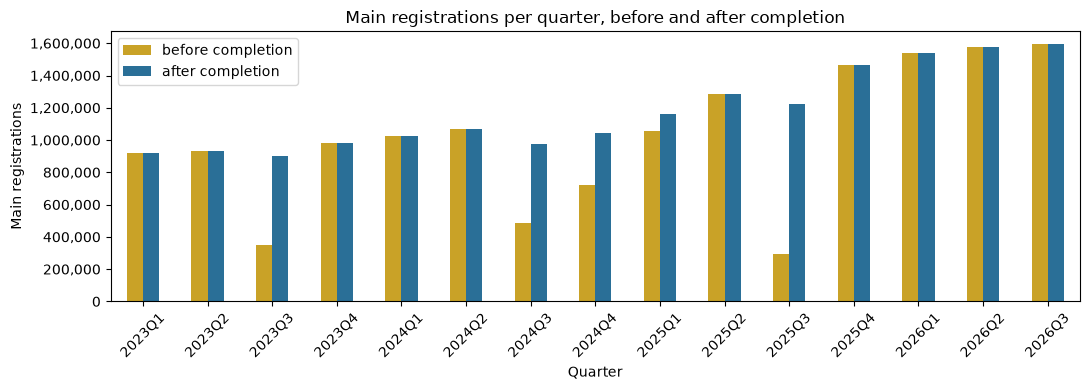

,before completion,after completion
snapshot_quarter,,
2023Q1,921307,921307
2023Q2,932438,932438
2023Q3,346660,899504
2023Q4,979464,979464
2024Q1,1022711,1022711
2024Q2,1069989,1069989
2024Q3,486770,975859
2024Q4,718406,1045953
2025Q1,1056507,1162198


In [15]:
# Main registrations per quarter before and after the completion of section 5.1 (a figure only; nothing is changed)
counts = pd.DataFrame({'before completion': observed_presence.sum(), 'after completion': presence.sum()}).reindex(QUARTERS)
ax = counts.plot.bar(figsize=(11, 4), rot=45, color=['#c9a227', '#2a6f97'],
                     title='Main registrations per quarter, before and after completion')
ax.set_xlabel('Quarter'); ax.set_ylabel('Main registrations'); ax.yaxis.set_major_formatter('{x:,.0f}')
plt.tight_layout()
for extension in ['svg', 'png']:
    plt.savefig(FIGURES / f'02_5.1_completion_before_after.{extension}', dpi=300)
plt.show()
counts

## 6. Stage 4 — The Survival Target

The survival check quarter is the quarterly record **four quarters after the founding quarter**. Because the
records are snapshots taken at the end of each quarter, the check takes place between 12 and 15 months after
founding: for example, a business founded in 2024 Q2 (1 April – 30 June 2024) is checked in the 2025 Q2 record.

| `survived_first_year` | `label_reason` | Rule |
|---|---|---|
| 1 | `present_at_check` | Present in the survival check quarter |
| 0 | `absent_at_check` | Absent from the survival check quarter and from every later record |
| 0 | `absent_at_check_reappeared_later` | Absent from the survival check quarter but present in a later record |
| — | `former_branch_registration` | A branch before its first record as a main registration (section 4.2): during its first year it was part of another business |
| — | `founded_before_records` | Founded before 2023 Q1: its first year is not observed |
| — | `check_after_records` | Its survival check quarter is after 2026 Q3 |

A business absent from the survival check quarter is recorded as **failed**, whether or not it appears again
later. The study measures whether the business was active at the end of its first year; a registration that was
not active at that point, for example because it was suspended for not submitting its annual confirmation
(Commercial Register Law, Article 15), did not complete its first year as an active business. Businesses that
reappear later are identified by their `label_reason`.

One further attribute describes how far each label can be relied upon, without changing it:

- `check_record_complete` is false when the survival check quarter is one of the incomplete quarters (2023 Q3,
  2024 Q3, 2024 Q4, 2025 Q1 or 2025 Q3; it concerns businesses founded in 2023 Q3, 2023 Q4, 2024 Q1 and 2024 Q3). A
  business active at its check but missing from the incomplete record, which then closed before the next complete
  record, cannot be completed and is recorded as failed, so the failure observed for these founding quarters may be
  higher than the true failure. The cell reports the failure rate with and without these businesses.

Businesses founded in an incomplete quarter are kept with their labels; the bias this creates is stated in the
limitations (section 10).

In [16]:
founding = businesses['founding_quarter'].astype('string')
has_date = founding.notna()
check = pd.Series(pd.NA, index=businesses.index, dtype='string')
check[has_date] = (pd.PeriodIndex(founding[has_date], freq='Q') + 4).astype(str)
businesses['survival_check_quarter'] = check

reason = pd.Series('founding_date_missing', index=businesses.index, dtype=object)
reason[(has_date & (founding < QUARTERS[0])).fillna(False)] = 'founded_before_records'
reason[(has_date & (founding >= QUARTERS[0]) & (check > QUARTERS[-1])).fillna(False)] = 'check_after_records'
eligible = (has_date & (founding >= QUARTERS[0]) & (check <= QUARTERS[-1])).fillna(False).astype(bool)
is_former_branch = pd.Series(businesses.index.isin(list(former_branch)), index=businesses.index)
reason[eligible & is_former_branch] = 'former_branch_registration'
eligible = eligible & ~is_former_branch

survived = pd.Series(pd.NA, index=businesses.index, dtype='Int8')
for quarter in sorted(check[eligible].unique()):
    rows = eligible & (check == quarter).fillna(False)
    present = presence.loc[rows, quarter]
    later = [q for q in QUARTERS if q > quarter]
    returned = presence.loc[rows, later].any(axis=1) if later else pd.Series(False, index=present.index)
    reason[rows[rows].index] = np.where(present, 'present_at_check',
                               np.where(returned, 'absent_at_check_reappeared_later', 'absent_at_check'))
    survived[rows[rows].index] = pd.array(np.where(present, 1, 0), dtype='Int8')
businesses['survived_first_year'] = survived
businesses['label_reason'] = reason.astype('category')
businesses['check_record_complete'] = ~businesses['survival_check_quarter'].isin(INCOMPLETE)


print(businesses['label_reason'].value_counts().to_string())
labelled = businesses[businesses['survived_first_year'].notna()]
failure = 1 - labelled.groupby('check_record_complete')['survived_first_year'].mean()
print(f"\nFailure rate, survival check in a complete record: {failure.get(True):.1%} | in an incomplete record: {failure.get(False):.1%} "
      f"({int((~labelled['check_record_complete']).sum()):,} businesses)")
summary = businesses[eligible].groupby('founding_quarter').agg(
    businesses=('label_reason', 'size'),
    survived=('survived_first_year', lambda s: int((s == 1).sum())),
    failed=('survived_first_year', lambda s: int((s == 0).sum())),
    of_which_reappeared_later=('label_reason', lambda s: int((s == 'absent_at_check_reappeared_later').sum())))
summary['survival rate'] = summary['survived'] / (summary['survived'] + summary['failed'])
summary.style.format({'survival rate': '{:.1%}', 'businesses': '{:,}', 'survived': '{:,}', 'failed': '{:,}', 'of_which_reappeared_later': '{:,}'})

label_reason
founded_before_records              913375
present_at_check                    739104
check_after_records                 305274
absent_at_check                     103261
former_branch_registration           31856
absent_at_check_reappeared_later      7886

Failure rate, survival check in a complete record: 11.4% | in an incomplete record: 16.6% (274,780 businesses)


,businesses,survived,failed,of_which_reappeared_later,survival rate
founding_quarter,,,,,
2023Q1,"47,926","39,490","8,436",131,82.4%
2023Q2,"42,109","34,818","7,291",150,82.7%
2023Q3,"51,636","39,279","12,357","2,146",76.1%
2023Q4,"64,253","53,447","10,806",801,83.2%
2024Q1,"71,207","61,330","9,877","1,210",86.1%
2024Q2,"92,278","84,280","7,998",71,91.3%
2024Q3,"87,684","75,075","12,609","2,565",85.6%
2024Q4,"95,043","83,876","11,167",528,88.3%
2025Q1,"102,423","89,028","13,395",132,86.9%


**Result.** 850,251 businesses founded between 2023 Q1 and 2025 Q3 received a label: 739,104 survived and 111,147
failed, of which 103,261 never appeared again and 7,886 reappeared in a later record. 31,856 former branches founded
in the same period received no label. Survival ranges from 76.1% (2023 Q3) to 93.5% (2025 Q3) across founding
quarters. Failure is 11.4% for the businesses whose survival check falls in a complete record, and 16.6% for the
274,780 whose check falls in an incomplete record.

**Interpretation.** The survival target is available for every founding quarter whose first year is observed.
Excluding the former branches removes most of the failed businesses that reappeared later (from 27,259 to 7,886),
since those were branches that became main registrations rather than businesses that closed. The failure rate is
still higher when the survival check falls in an incomplete record, which is consistent with the risk described
for `check_record_complete`.

### 6.1 Failed Businesses That Reappear Later

This cell describes, for information, the failed businesses that appear again in a later record, and how many
quarters after their survival check quarter they reappear.

In [17]:
reappeared = businesses.index[businesses['label_reason'] == 'absent_at_check_reappeared_later']
flags_presence = presence.loc[reappeared].to_numpy()
check_position = businesses.loc[reappeared, 'survival_check_quarter'].map({q: i for i, q in enumerate(QUARTERS)}).to_numpy()
after_check = np.arange(len(QUARTERS))[None, :] > check_position[:, None]
first_after = np.where(flags_presence & after_check, np.arange(len(QUARTERS))[None, :], 99).min(axis=1)
gaps = pd.Series(first_after - check_position, name='quarters until reappearance')
distribution = gaps.value_counts().sort_index().rename('businesses').to_frame()
distribution['cumulative share'] = (distribution['businesses'].cumsum() / len(gaps)).map('{:.1%}'.format)
print(f'Failed businesses that reappear in a later record: {len(gaps):,} '
      f'({len(gaps) / int((businesses["survived_first_year"] == 0).sum()):.1%} of all failed businesses)')
distribution

Failed businesses that reappear in a later record: 7,886 (7.1% of all failed businesses)


,businesses,cumulative share
quarters until reappearance,,
1,4230,53.6%
2,3149,93.6%
3,264,96.9%
4,181,99.2%
5,60,100.0%
6,2,100.0%


**Result.** 7,886 failed businesses (7.1% of all failed businesses) appear again in a later record: 53.6% one
quarter after their survival check and 99.2% within four quarters.

**Interpretation.** One failed business in fourteen returns later, typically after a suspension of its registration.
Under the definition of the study they are recorded as failed, since they were not active at the end of their first
year.

### 6.2 Conversions of Sole Proprietorships into Companies

**Research question.** Do conversions of sole proprietorships into companies make a continuing business appear
as a failed business, or an existing business appear as a newly founded one, and could they explain the large
number of companies founded in 2024 Q2?

**Legal and regulatory context.**

| Source | Provision | Relevance |
|---|---|---|
| [Companies Law](https://mc.gov.sa/ar/DO/com-2022.pdf), Article 220(3), in force since 19 January 2023 | The owners of sole proprietorships may transfer their assets to any form of company established under the law; the owners remain liable for the earlier debts of the sole proprietorship unless the creditors expressly accept otherwise. | The article permits the conversion. It does not state whether the registration number or the founding date changes. |
| Companies Law, Article 223 | The transformation of a company into another form does not create a new legal person. | Applies to companies changing form, not to sole proprietorships. |
| [Ministry of Commerce, Merchant Guide](https://mc.gov.sa/ar/guides/MerchantGuide/Documents/MCIDoc.pdf#page=41), page 41 (file dated January 2023) | Step 5 of the service "conversion from an establishment to a company" offers to keep the registration and its date, and to keep the name as the main name. | A conversion may keep the same registration number and founding date. |
| [Ministry of Commerce, service "conversion from a sole proprietorship to a company"](https://mc.gov.sa/ar/eservices/Pages/ServiceDetails.aspx?sID=52) | The registration must be active. | Does not state whether the number or the date is kept. |
| Commercial Register Law, in force since 5 Shawwal 1446 AH (3 April 2025) | No provision on the conversion of a sole proprietorship was identified. | Unresolved: its effect on conversions is not assumed. |

Two scenarios are therefore possible, and both are examined:

| Scenario | What happens in the records | Detection | Nature of the result |
|---|---|---|---|
| A | The company receives a new registration number; the registration of the sole proprietorship ends | Same core name (the name without its legal-form words), same city, and the sole proprietorship last recorded in the company's founding quarter or the quarter after it | **Possible conversion** (heuristic matching; the owners' identities are not in the records) |
| B | The same registration number continues with a company legal form | The legal form of the same registration number changes from sole proprietorship to a company between two consecutive records in which it appears | **Observed legal-form transition** |

The founding date, the name and the city before and after each transition are compared, and transitions that
change back and forth are separated as inconsistent records. Neither scenario changes the survival target or
removes any record.

In [18]:
LEGAL_WORDS = r'\b(شركه|مؤسسه|فرديه|ذات|مسؤوليه|مسئوليه|المحدوده|محدوده|شخص|واحد|مساهمه|مبسطه|تضامنيه|توصيه|بسيطه|قابضه|مهنيه)\b'
def core_name(name):
    text = re.sub('[إأآ]', 'ا', str(name)).replace('ة', 'ه').replace('ى', 'ي')
    return re.sub(r'\s+', ' ', re.sub(LEGAL_WORDS, ' ', text)).strip()

SOLE = 'مؤسسة فردية'
COMPANY_FORMS = ['الشركة ذات المسؤولية المحدودة', 'شركة المساهمة', 'شركة المساهمة المبسطة', 'شركة التضامن', 'شركة التوصية البسيطة']

# Scenario A: a new company and a sole proprietorship with the same core name and city that ends at the same time
flags = presence.to_numpy()
last_present = pd.Series(np.array(QUARTERS)[len(QUARTERS) - 1 - flags[:, ::-1].argmax(axis=1)], index=presence.index)
sole = businesses['legal_form'] == SOLE
ended = sole & (last_present < QUARTERS[-1])
closing = pd.DataFrame({'sole_number': businesses.index[ended],
                        'core': businesses.loc[ended, 'business_name'].map(core_name).to_numpy(),
                        'city': businesses.loc[ended, 'city'].astype(str).to_numpy(),
                        'last_quarter': last_present[ended].to_numpy()})
company = businesses['legal_form'].isin(COMPANY_FORMS) & businesses['founding_quarter'].notna()
opening = pd.DataFrame({'number': businesses.index[company],
                        'core': businesses.loc[company, 'business_name'].map(core_name).to_numpy(),
                        'city': businesses.loc[company, 'city'].astype(str).to_numpy(),
                        'founding_quarter': businesses.loc[company, 'founding_quarter'].astype(str).to_numpy()})
pairs = opening.merge(closing, on=['core', 'city'])
following = pairs['founding_quarter'].map(lambda q: str(pd.Period(q, 'Q') + 1))
pairs = pairs[(pairs['last_quarter'] == pairs['founding_quarter']) | (pairs['last_quarter'] == following)]
businesses['possible_conversion'] = businesses.index.isin(pairs['number'])
del closing, opening
print(f'Scenario A: {len(pairs):,} pairs | {pairs["number"].nunique():,} companies | {pairs["sole_number"].nunique():,} sole proprietorships')
print(f'  companies matched to more than one sole proprietorship: {int((pairs.groupby("number").size() > 1).sum()):,}')
print(f'  sole proprietorships matched to more than one company: {int((pairs.groupby("sole_number").size() > 1).sum()):,}')

# Scenario B: the same registration number changes its legal form between two consecutive records
known_form = (records['registration_type'] == MAIN) & records['registration_number'].notna() & ~records['repeated_in_quarter'] \
             & records['legal_form'].notna()
history = records.loc[known_form, ['registration_number', 'snapshot_quarter', 'legal_form', 'founding_date', 'business_name', 'city']].copy()
history['snapshot_quarter'] = history['snapshot_quarter'].astype(str)
history['legal_form'] = history['legal_form'].astype(str)
history = history.sort_values(['registration_number', 'snapshot_quarter'], kind='stable')
before = history.groupby('registration_number', sort=False).shift(1)
step = history[before['snapshot_quarter'].notna() & (before['legal_form'] != history['legal_form'])].join(before.add_suffix('_before'))
print(f'\nLegal-form changes of the same registration number between consecutive records: {len(step):,}')
print('Changes by quarter of the later record:', step['snapshot_quarter'].value_counts().sort_index().to_dict())
transitions = step[(step['legal_form_before'] == SOLE) & step['legal_form'].isin(COMPANY_FORMS)].copy()
to_sole = step[step['legal_form_before'].isin(COMPANY_FORMS) & (step['legal_form'] == SOLE)]
forms = history[history['registration_number'].isin(transitions['registration_number'])].groupby('registration_number')['legal_form'].agg(list)
def form_pattern(values):
    kinds = ['S' if v == SOLE else 'C' if v in COMPANY_FORMS else 'O' for v in values]
    return ''.join(k for i, k in enumerate(kinds) if i == 0 or k != kinds[i - 1])
transitions['consistent'] = transitions['registration_number'].map(forms.map(form_pattern)).eq('SC')
transitions['founding_date_kept'] = transitions['founding_date'] == transitions['founding_date_before']
transitions['name_kept'] = transitions['business_name'] == transitions['business_name_before']
transitions['core_name_kept'] = transitions['business_name'].map(core_name) == transitions['business_name_before'].map(core_name)
transitions['city_kept'] = transitions['city'].astype(str) == transitions['city_before'].astype(str)
businesses['legal_form_transition_quarter'] = businesses.index.map(
    transitions.set_index('registration_number')['snapshot_quarter']).astype('string')
n = len(transitions)
print(f'\nScenario B: {n:,} transitions from sole proprietorship to company on {transitions["registration_number"].nunique():,} registration numbers')
print(f'  consistent (sole proprietorship, then company only): {int(transitions["consistent"].sum()):,} | changing back and forth: {n - int(transitions["consistent"].sum()):,}')
print(f'  transitions from company to sole proprietorship: {len(to_sole):,}')
print(f'  founding date kept: {int(transitions["founding_date_kept"].sum()):,} | changed: {n - int(transitions["founding_date_kept"].sum()):,}')
print(f'  name identical: {int(transitions["name_kept"].sum()):,} ({transitions["name_kept"].mean():.1%}) | '
      f'core name identical: {int(transitions["core_name_kept"].sum()):,} ({transitions["core_name_kept"].mean():.1%}) | '
      f'same city: {int(transitions["city_kept"].sum()):,} ({transitions["city_kept"].mean():.1%})')
print('  company form after the transition:', transitions['legal_form'].value_counts().to_dict())
print(f'\nOverlap: companies of scenario A with a scenario B transition: {len(set(pairs["number"]) & set(transitions["registration_number"])):,} | '
      f'sole proprietorships of scenario A with a scenario B transition: {len(set(pairs["sole_number"]) & set(transitions["registration_number"])):,}')
del history, before, step, forms
_ = gc.collect()

Scenario A: 832 pairs | 563 companies | 386 sole proprietorships
  companies matched to more than one sole proprietorship: 91
  sole proprietorships matched to more than one company: 78



Legal-form changes of the same registration number between consecutive records: 21,536
Changes by quarter of the later record: {'2025Q2': 4965, '2025Q4': 5220, '2026Q1': 6684, '2026Q2': 1695, '2026Q3': 2972}



Scenario B: 20,325 transitions from sole proprietorship to company on 20,325 registration numbers
  consistent (sole proprietorship, then company only): 20,322 | changing back and forth: 3
  transitions from company to sole proprietorship: 37
  founding date kept: 20,325 | changed: 0
  name identical: 1,635 (8.0%) | core name identical: 9,172 (45.1%) | same city: 16,404 (80.7%)
  company form after the transition: {'الشركة ذات المسؤولية المحدودة': 19877, 'شركة المساهمة': 281, 'شركة التضامن': 90, 'شركة المساهمة المبسطة': 67, 'شركة التوصية البسيطة': 10}

Overlap: companies of scenario A with a scenario B transition: 0 | sole proprietorships of scenario A with a scenario B transition: 0


**Result.** Scenario A matches 563 companies with 386 sole proprietorships (832 pairs); 91 companies match more than one sole
proprietorship and 78 sole proprietorships match more than one company. Scenario B finds 20,325 transitions from
sole proprietorship to company under the same registration number, 19,877 of them into a limited liability company.
Of these, 20,322 are consistent and 3 change back and forth; 37 registration numbers change from a company to a
sole proprietorship. The founding date is kept in all 20,325 transitions. The name is identical in 1,635
transitions (8.0%) and the name without its legal-form words in 9,172 (45.1%); the city is the same in 16,404
(80.7%). No business is detected by both scenarios. No legal-form change of any kind is observed for the same
registration number before 2025 Q2: all 21,536 changes appear in the records from 2025 Q2 onwards.

**Interpretation.** Both scenarios occur. Scenario B is an observed fact of the records: the same registration number continues with a
company legal form and its original founding date, as the Merchant Guide allows, while the name usually changes.
Scenario A remains a possible conversion only, and its matches are not unique for about one company in seven. The
absence of any legal-form change before 2025 Q2 coincides with the first record under the Commercial Register Law
in force from 3 April 2025 and with other changes of the files in that quarter (Notebook 01, findings 6 and 9). The
records do not show whether conversions before 2025 Q2 received a new registration number or whether the earlier
files did not update the legal form; this question is unresolved.

#### 6.2.1 Conversions by Quarter

For scenario A, the denominator is the number of companies founded in the quarter. For scenario B, it is the number
of sole proprietorships in the most recent **complete** record before the quarter, since an incomplete record would
understate it (section 5.1).

In [19]:
window = [q for q in QUARTERS if '2023Q1' <= q <= '2025Q3']
in_window = company & businesses['founding_quarter'].isin(window)
sole_in_record = {q: int(((records['snapshot_quarter'] == q) & (records['registration_type'] == MAIN) & (records['legal_form'] == SOLE)
                          & records['registration_number'].notna() & ~records['repeated_in_quarter']).sum()) for q in COMPLETE}
rows = []
for quarter in QUARTERS:
    previous_complete = [q for q in COMPLETE if q < quarter]
    t = transitions[transitions['snapshot_quarter'] == quarter]
    denominator = sole_in_record[previous_complete[-1]] if previous_complete else np.nan
    rows.append({'quarter': quarter,
                 'companies founded': int((businesses.loc[in_window, 'founding_quarter'] == quarter).sum()) if quarter in window else np.nan,
                 'A: possible conversions': pairs.loc[pairs['founding_quarter'] == quarter, 'number'].nunique() if quarter in window else np.nan,
                 'B: transitions': len(t), 'B: founding date kept': int(t['founding_date_kept'].sum()),
                 'B: founding date changed': int((~t['founding_date_kept']).sum()),
                 'sole proprietorships in the previous complete record': denominator})
by_quarter = pd.DataFrame(rows).set_index('quarter')
by_quarter['A: share of companies founded'] = by_quarter['A: possible conversions'] / by_quarter['companies founded']
by_quarter['B: per 1,000 sole proprietorships'] = 1000 * by_quarter['B: transitions'] / by_quarter['sole proprietorships in the previous complete record']
by_quarter.style.format({'A: share of companies founded': '{:.2%}', 'B: per 1,000 sole proprietorships': '{:.1f}'}, na_rep='—', precision=0, thousands=',')

,companies founded,A: possible conversions,B: transitions,B: founding date kept,B: founding date changed,sole proprietorships in the previous complete record,A: share of companies founded,"B: per 1,000 sole proprietorships"
quarter,,,,,,,,
2023Q1,"7,136",2,0,0,0,—,0.03%,—
2023Q2,"6,780",2,0,0,0,"761,461",0.03%,0.0
2023Q3,"8,986",0,0,0,0,"767,172",0.00%,0.0
2023Q4,"13,792",4,0,0,0,"767,172",0.03%,0.0
2024Q1,"22,397",40,0,0,0,"794,461",0.18%,0.0
2024Q2,"46,551",26,0,0,0,"818,688",0.06%,0.0
2024Q3,"33,475",7,0,0,0,"825,598",0.02%,0.0
2024Q4,"29,752",42,0,0,0,"825,598",0.14%,0.0
2025Q1,"34,424",97,0,0,0,"825,598",0.28%,0.0


**Result.** Possible conversions of scenario A are at most 0.28% of the companies founded in any quarter (97 of 34,424 in 2025
Q1); in 2024 Q2 they are 26 of 46,551 (0.06%). Scenario B shows no transition before 2025 Q2, then 4,599 in 2025
Q2, 4,927 in 2025 Q4, 6,379 in 2026 Q1, 1,608 in 2026 Q2 and 2,812 in 2026 Q3, between 1.6 and 6.5 per 1,000 sole
proprietorships of the previous complete record. None of them changes the founding date.

**Interpretation.** Conversions under a new registration number are rare in every quarter. Conversions under the same registration
number concern a few sole proprietorships in every thousand each quarter from 2025 Q2. Because they keep their
founding date and their registration number, they never appear as newly founded businesses.

#### 6.2.2 Companies Founded in 2024 Q2

The number of companies founded rises from 22,397 in 2024 Q1 to 46,551 in 2024 Q2 (section 6). This cell
examines whether the increase comes from conversions, from sole proprietors choosing a company instead, or from a
concentration in time or in activity. The word مقاول (contractor) in the business name is used as an indicator of
contracting activity.

In [20]:
recent = businesses[company & businesses['founding_date'].between('2023-07-01', '2025-03-31')].copy()
recent['month'] = recent['founding_date'].dt.to_period('M').astype(str)
recent['contracting_name'] = recent['business_name'].astype(str).str.contains('مقاول')
monthly = recent.groupby('month').agg(companies=('contracting_name', 'size'), with_contracting_name=('contracting_name', 'sum'))
monthly['share with contracting name'] = monthly['with_contracting_name'] / monthly['companies']

compare = []
for quarter in ['2024Q1', '2024Q2']:
    founded = businesses[businesses['founding_quarter'] == quarter]
    companies = founded[founded['legal_form'].isin(COMPANY_FORMS)]
    compare.append({'founding quarter': quarter, 'companies founded': len(companies),
                    'of which with a contracting name': int(companies['business_name'].astype(str).str.contains('مقاول').sum()),
                    'sole proprietorships founded': int((founded['legal_form'] == SOLE).sum()),
                    'A: possible conversions': pairs.loc[pairs['founding_quarter'] == quarter, 'number'].nunique(),
                    'B: transitions in the quarter': int((transitions['snapshot_quarter'] == quarter).sum())})
compare = pd.DataFrame(compare).set_index('founding quarter')
print(compare.to_string())
print('\nIncrease from 2024 Q1 to 2024 Q2:', (compare.loc['2024Q2'] - compare.loc['2024Q1']).to_dict())
may = recent[recent['month'] == '2024-05']
print('\nCompanies founded in May 2024 by day of the week:', may['founding_date'].dt.day_name().value_counts().to_dict())
monthly.style.format({'share with contracting name': '{:.1%}'}, thousands=',')

                  companies founded  of which with a contracting name  sole proprietorships founded  A: possible conversions  B: transitions in the quarter
founding quarter                                                                                                                                           
2024Q1                        22397                              7070                         51770                       40                              0
2024Q2                        46551                             20406                         48666                       26                              0

Increase from 2024 Q1 to 2024 Q2: {'companies founded': 24154, 'of which with a contracting name': 13336, 'sole proprietorships founded': -3104, 'A: possible conversions': -14, 'B: transitions in the quarter': 0}

Companies founded in May 2024 by day of the week: {'Thursday': 7324, 'Wednesday': 5283, 'Tuesday': 3466, 'Monday': 2338, 'Sunday': 1755, 'Friday': 1414, 'Saturda

,companies,with_contracting_name,share with contracting name
month,,,
2023-07,"2,494",303,12.1%
2023-08,"3,049",444,14.6%
2023-09,"3,443",666,19.3%
2023-10,"4,282",946,22.1%
2023-11,"4,250","1,006",23.7%
2023-12,"5,260","1,282",24.4%
2024-01,"5,291","1,265",23.9%
2024-02,"6,794","2,053",30.2%
2024-03,"10,312","3,752",36.4%


**Result.** From 2024 Q1 to 2024 Q2, the number of companies founded increases by 24,154 (from 22,397 to 46,551). Possible
conversions of scenario A fall from 40 to 26, scenario B shows no transition in either quarter, and the number of
sole proprietorships founded falls by only 3,104 (from 51,770 to 48,666). Companies with a contracting name
increase by 13,336 (from 7,070 to 20,406), 55.2% of the increase; their share of the companies founded rises from
23.9% in January 2024 to 45.3% in May 2024. May 2024 alone has 22,383 companies founded, against 11,701 in April
and 12,467 in June, mostly on Thursdays (7,324) and Wednesdays (5,283); July 2024 is also high (19,731).

**Interpretation.** Conversions explain at most 26 of the 24,154 additional companies, and the small fall in sole proprietorships
cannot account for the rest. The increase is concentrated in time (May and July 2024) and in contracting companies.
Whether it reflects newly established businesses, an administrative change in registration or a regulatory
requirement cannot be determined from the records, and no official source explaining it has been identified; no
cause is therefore attributed. The businesses are kept with their labels.

#### 6.2.3 Implications for the Survival Target

This cell measures how many labels each scenario could affect. The legal form after a transition is observed after
the founding and is therefore never an input of the model; it is not stored in the dataset.

In [21]:
labelled = businesses[businesses['survived_first_year'].notna()]
labelled_sole = labelled[labelled['legal_form'] == SOLE]
failed_sole = labelled_sole[labelled_sole['survived_first_year'] == 0]
labelled_company = labelled[labelled['legal_form'].isin(COMPANY_FORMS)]
converted = labelled[labelled.index.isin(transitions['registration_number'])]
before_check = converted['legal_form_transition_quarter'] <= converted['survival_check_quarter']
print(f'A: failed sole proprietorships paired with a possible conversion: {int(failed_sole.index.isin(pairs["sole_number"]).sum()):,} '
      f'of {len(failed_sole):,} failed sole proprietorships ({failed_sole.index.isin(pairs["sole_number"]).mean():.2%})')
print(f'A: labelled companies flagged as a possible conversion: {int(labelled_company["possible_conversion"].sum()):,} '
      f'of {len(labelled_company):,} labelled companies ({labelled_company["possible_conversion"].mean():.2%})')
print(f'B: labelled businesses with a later transition: {len(converted):,} | survived {int((converted["survived_first_year"] == 1).sum()):,} | '
      f'failed {int((converted["survived_first_year"] == 0).sum()):,}')
print(f'B: transition at or before the survival check: {int(before_check.sum()):,} | after it: {int((~before_check).sum()):,}')
print(f'B: legal form stored in the dataset is the sole proprietorship (the form at founding): {int((converted["legal_form"] == SOLE).sum()):,} of {len(converted):,}')
rate = labelled[labelled['legal_form'].isin(COMPANY_FORMS)].groupby('possible_conversion')['survived_first_year'].mean()
print(f'Survival rate of labelled companies: possible conversion {rate.get(True, float("nan")):.1%} | other companies {rate.get(False, float("nan")):.1%}')
del pairs, transitions, recent
_ = gc.collect()

A: failed sole proprietorships paired with a possible conversion: 200 of 97,506 failed sole proprietorships (0.21%)
A: labelled companies flagged as a possible conversion: 304 of 278,115 labelled companies (0.11%)
B: labelled businesses with a later transition: 8,800 | survived 8,548 | failed 252
B: transition at or before the survival check: 3,729 | after it: 5,071
B: legal form stored in the dataset is the sole proprietorship (the form at founding): 8,800 of 8,800
Survival rate of labelled companies: possible conversion 89.8% | other companies 95.1%


**Result.** Under scenario A, at most 200 failed sole proprietorships (0.21% of 97,506) may have continued as a company, and
at most 304 labelled companies (0.11% of 278,115) may be existing businesses recorded as new; these companies
survive at 89.8%, against 95.1% for other companies. Under scenario B, 8,800 labelled businesses later become a
company: 8,548 survived and 252 failed; 3,729 change at or before their survival check and 5,071 after it. All
8,800 keep their form at founding, the sole proprietorship, in the dataset.

**Interpretation.** A conversion under the same registration number does not create a false failure, because the registration continues
and is present at the check; it keeps the founding date, so the tracking of a business by its registration number
remains exact. A conversion under a new registration number cannot be confirmed: scenario A relies on the name and
the city only, the owners' identities are not in the records, and one company in six matches more than one sole
proprietorship. Without proof of a conversion, the matched company and sole proprietorship are treated as
**two separate businesses**, each with its own label, and no attribute of scenario A is stored.

**Limitations.** (1) Scenario A relies on the name and the city only: a conversion that also changed the name or the city is not
detected, and the matches of 91 companies are not unique. (2) The owners' identities are not in the records, so no
conversion of scenario A is confirmed. (3) No legal-form change is observed before 2025 Q2, and the reason is
unresolved. (4) The effect of the Commercial Register Law of 2025 on conversions has not been established from an
official text. (5) The word مقاول indicates contracting activity only approximately.

**Implications for the reliability of the survival target.** The survival target is not changed. The label noise attributable to conversions
is small: at most 0.21% of the failed sole proprietorships and 0.11% of the labelled companies under scenario A, and
none under scenario B. The attributes of both scenarios describe events after the founding and are not stored in the
dataset.

## 7. Stage 5 — Economic Sector

The quarterly records do not contain the economic activity of a business, although the registry holds it: every
registration request must state the type of activity (Implementing Regulation of the Commercial Register Law,
Article 3), and the trader's activities are part of the registry's data (Article 15). The Ministry of Commerce
publishes these activities in a separate set of files that link each active registration to its activities in the
National Classification of Economic Activities (SSIC). They are the official record of each business's activity
([Commercial Register Law and its Implementing Regulation](https://mc.gov.sa/ar/Regulations/pages/details.aspx?lawId=3d536f10-11ce-49db-9153-b204016f4fca)).

These files cannot be used directly as an input of the survival model: they list only the registrations still
active when each file was produced, so a business that had already closed is absent from them. They are used
instead as the **answer key** from which the words that indicate each sector are counted, and against which the inferred sector is checked. The sector of every
business is then inferred from its own business name, which is known at its founding:

1. **Keywords:** a word or two-word phrase used in the names of at least **30** businesses, at least **70%**
   of which are registered in the same section.
2. **Classification rules** of the team (`ml/src/isic_classifier.py`), for names without a keyword.
3. Otherwise **`unclassified`**.

The keywords are counted only from businesses that have **no survival label** (founded before 2023 Q1 or after
2025 Q3) and no tie between sections, so that no business used to evaluate or train the model contributes to them.

### 7.1 Official Section of Each Registration

The registered-activity files of the Ministry of Commerce (2023, 2024 and 2025) record the official activities of
each registration. They serve as the **answer key** of the sector classification, in two ways only: the keywords are
counted from them (section 7.2), and the inferred sector is checked against them (section 7.4). They are never used
to give a sector to a business and are never an input of the survival model, since a registration listed in these
files is, in most cases, one that was still active; using them as an input would reveal the outcome.

A registration may hold several activities, which need not be related (Commercial Register Law, Article 9), and the
files do not identify a main activity. The official section of a registration is taken as the section to which most
of its activities belong. When two or more sections hold the same number of activities, the registration is marked
as **tied**: it is left out of the keyword counting (section 7.2), and in the evaluation (section 7.4) its inferred
sector is counted as correct if it matches any of the tied sections. When a registration appears in the activity
files of more than one year, its official section is taken from the most recent year.

In [22]:
import glob
from collections import Counter

section_letter = dict(zip([str(i) for i in range(1, 22)], 'ABCDEFGHIJKLMNOPQRSTU'))
official_parts, section_names = [], {}
for year, pattern in [('2025', 'CR_ISIC_2025*'), ('2024', 'CR_ISISC_2024_PART*'), ('2023', 'CR_ISISC_2023_PART*')]:
    frames = []
    for path in sorted(glob.glob(str(PIPE / '00_raw' / 'activity' / f'{pattern}.parquet'))):
        part = pd.read_parquet(path, columns=['الرقم الوطني', 'كود النشاط المستوى 1', 'وصف النشاط المستوى 1'])
        part.columns = ['registration_number', 'section_code', 'section_name']
        frames.append(part)
    activities = pd.concat(frames, ignore_index=True)
    activities['registration_number'] = activities['registration_number'].str.strip()
    activities['section'] = activities['section_code'].str.strip().map(section_letter)
    section_names.update(activities.drop_duplicates('section').set_index('section')['section_name'].str.strip().to_dict())
    counts = activities.groupby(['registration_number', 'section'], observed=True).size().rename('activities').reset_index()
    most = counts.groupby('registration_number')['activities'].transform('max')
    main_section = (counts[counts['activities'] == most].sort_values(['registration_number', 'section'])
                    .groupby('registration_number')['section'].agg('|'.join))
    official_parts.append(main_section)
    print(f'{year}: {len(activities):,} activity records | {len(main_section):,} registrations | '
          f'tied: {int(main_section.str.contains("|", regex=False).sum()):,} ({main_section.str.contains("|", regex=False).mean():.1%})')
    del activities, counts, frames
    gc.collect()

official_section = official_parts[0]
for part in official_parts[1:]:
    official_section = official_section.combine_first(part)
official = businesses.index.to_series().map(official_section)
del official_parts
official_tied = official.str.contains('|', regex=False).fillna(False).astype(bool)
print(f'Businesses in our table with an official section: {official.notna().sum():,} of {len(businesses):,} | '
      f'tied: {int(official_tied.sum()):,} ({official_tied.sum() / official.notna().sum():.1%})')

2025: 19,113,195 activity records | 1,830,271 registrations | tied: 73,898 (4.0%)


2024: 12,047,491 activity records | 1,563,648 registrations | tied: 54,266 (3.5%)


2023: 9,121,160 activity records | 1,327,713 registrations | tied: 45,849 (3.5%)


Businesses in our table with an official section: 1,718,878 of 2,100,756 | tied: 64,903 (3.8%)


**Result.** The activity files contain 19,113,195 activity records for 1,830,271 registrations in 2025, 12,047,491
for 1,563,648 in 2024 and 9,121,160 for 1,327,713 in 2023. An official section is known for 1,718,878 of the
2,100,756 businesses; 64,903 of them (3.8%) have a tie between sections, from 3.5% of the registrations in 2023 and
2024 to 4.0% in 2025.

**Interpretation.** About four businesses in five have an official section against which the keywords can be
counted and the inferred sector checked. Ties concern a small share of the registrations and are no longer resolved
by an arbitrary order of the sections.

### 7.2 Counting the Keywords

The keywords are obtained by counting, not by training a model. Each business name is split into words and
two-word phrases, after harmonising spelling (أ/إ/آ → ا, ة → ه, ى → ي) and removing words that describe the legal
form or carry no activity (for example شركة، مؤسسة، للتجارة). For each word, the number of businesses using it and
the section in which they are registered are counted. A word becomes a keyword when it is used by at least 30
businesses and at least 70% of them share one section. Only businesses without a survival label (founded before
2023 Q1 or after 2025 Q3) and without a tied official section are counted, so that no business used to train or
evaluate the survival model contributes a keyword. The list is saved in `ml/reports/02_sector_keywords.csv` for
review. Keywords removed by the team after review are listed in `ml/reports/02_sector_keywords_removed.csv` and are
excluded here.

In [23]:
MIN_BUSINESSES, MIN_SHARE = 30, 0.70
NON_ACTIVITY_WORDS = set('شركه مؤسسه فرديه ذات مسؤوليه مسئوليه المحدوده محدوده شخص واحد مساهمه مبسطه تضامنيه توصيه '
                         'بسيطه قابضه مهنيه للتجاره التجاريه تجاره التجاره والتجاره لتجاره للتجارة وشركاه واخوانه واولاده '
                         'العربيه السعوديه الوطنيه المتحده الحديثه الدوليه العالميه الاولي الاول الخليج الشرق'.split())

def words_of(name):
    text = re.sub('[إأآ]', 'ا', str(name)).replace('ة', 'ه').replace('ى', 'ي')
    text = re.sub(r'[^\u0621-\u064A\s]', ' ', text)
    tokens = [w for w in text.split() if len(w) >= 3 and w not in NON_ACTIVITY_WORDS]
    return list(dict.fromkeys(tokens + [f'{a} {b}' for a, b in zip(tokens, tokens[1:])]))

founding = businesses['founding_quarter'].fillna('0000')
counting = official.notna() & ~official_tied & businesses['survived_first_year'].isna() & ((founding < QUARTERS[0]) | (founding > '2025Q3'))
pairs, totals = Counter(), Counter()
for name, section in zip(businesses.loc[counting, 'business_name'], official[counting]):
    for word in words_of(name):
        pairs[(word, section)] += 1
        totals[word] += 1

by_word = {}
for (word, section), n in pairs.items():
    by_word.setdefault(word, []).append((n, section))
removed_path = REPORTS / '02_sector_keywords_removed.csv'
removed = set(pd.read_csv(removed_path)['keyword']) if removed_path.exists() else set()
rows = []
for word, counts in by_word.items():
    ranked = sorted(counts, reverse=True)
    n, section = ranked[0]
    if totals[word] >= MIN_BUSINESSES and n / totals[word] >= MIN_SHARE and word not in removed:
        second = ranked[1] if len(ranked) > 1 else (0, '')
        rows.append({'keyword': word, 'sector': section, 'sector_name': section_names.get(section, ''),
                     'businesses_with_keyword': totals[word], 'of_which_in_this_sector': n,
                     'share': round(n / totals[word], 4), 'second_sector': second[1],
                     'businesses_in_second_sector': second[0]})
keywords = pd.DataFrame(rows).sort_values('businesses_with_keyword', ascending=False)
keywords.to_csv(REPORTS / '02_sector_keywords.csv', index=False, encoding='utf-8-sig')
keyword_section = dict(zip(keywords['keyword'], zip(keywords['sector'], keywords['share'])))
del pairs, totals, by_word
_ = gc.collect()
print(f'Counting set: {int(counting.sum()):,} businesses | keywords: {len(keywords):,} | removed after review: {len(removed)}')
keywords.head(15)

Counting set: 841,840 businesses | keywords: 3,483 | removed after review: 0


,keyword,sector,sector_name,businesses_with_keyword,of_which_in_this_sector,share,second_sector,businesses_in_second_sector
2,للمقاولات,F,التشييد,140344,124657,0.8882,G,5227
3,العامه,F,التشييد,58254,50279,0.8631,N,2537
4,للمقاولات العامه,F,التشييد,53109,48225,0.9080,G,1948
20,لتقديم,I,أنشطة خدمات الاقامة والطعام,46983,44750,0.9525,G,1000
21,الوجبات,I,أنشطة خدمات الاقامة والطعام,34304,32741,0.9544,G,648
22,لتقديم الوجبات,I,أنشطة خدمات الاقامة والطعام,34257,32698,0.9545,G,647
0,السيارات,G,تجارة الجملة والتجزئة وإصلاح المركبات ذات المحركات والد...,33250,31445,0.9457,N,790
71,محل,G,تجارة الجملة والتجزئة وإصلاح المركبات ذات المحركات والد...,26979,23518,0.8717,I,1644
15,الغذائيه,G,تجارة الجملة والتجزئة وإصلاح المركبات ذات المحركات والد...,23725,21835,0.9203,I,741
34,مطعم,I,أنشطة خدمات الاقامة والطعام,22637,21893,0.9671,G,347


**Result.** The keywords were counted from 841,840 businesses without a survival label and without a tie, and 3,483
keywords were retained. The most frequent include للمقاولات (construction, 88.8% of 140,344 businesses), لتقديم
الوجبات (food service, 95.5%) and مطعم (food service, 96.7%).

**Interpretation.** The keywords are activity words that point clearly to one section; the full list is saved in
`ml/reports/02_sector_keywords.csv` for review.

### 7.3 Assignment of the Sector

For each business, the sector is the section of the strongest keyword found in its name (the highest share, a
two-word phrase before a single word). If its name contains no keyword, the team's classification rules are
applied; they must first pass their self-test, and only a sure classification (flag `ok` or `division_unclear`)
is used. Otherwise the sector is `unclassified`. The attribute `sector_source` records which step gave the
sector: `keyword`, `rule` or `unclassified`.

In [24]:
import importlib
import isic_classifier
importlib.reload(isic_classifier)
from isic_classifier import RESULT, UNCLASSIFIED, classify_tuple, self_test

assert self_test(), 'The classification rules failed their self-test.'
def by_keyword(name):
    found = [(keyword_section[w][1], ' ' in w, w) for w in words_of(name) if w in keyword_section]
    return keyword_section[max(found)[2]][0] if found else ''

names = businesses['business_name'].fillna('')
unique_names = names.unique()
keyword_of = {name: by_keyword(name) for name in unique_names}
rule_of = {}
for name in unique_names:
    section, _, _, _, flag, _ = classify_tuple(name) if name else UNCLASSIFIED
    rule_of[name] = section if flag in ('ok', 'division_unclear') and section else ''
from_keyword, from_rule = names.map(keyword_of), names.map(rule_of)
businesses['sector'] = np.where(from_keyword != '', from_keyword, np.where(from_rule != '', from_rule, 'unclassified'))
businesses['sector_source'] = pd.Categorical(np.select([from_keyword != '', from_rule != ''], ['keyword', 'rule'], 'unclassified'))
rules_only = from_rule.where(from_rule != '', 'unclassified')
del keyword_of, rule_of, unique_names
gc.collect()
print(businesses.loc[businesses['founding_quarter'].fillna('0000') >= QUARTERS[0], 'sector_source'].value_counts(normalize=True).map('{:.1%}'.format).to_string())

Self-test: 15 / 15 correct


sector_source
keyword         50.1%
unclassified    44.9%
rule             5.0%


**Result.** The classification rules pass their self-test (15 of 15). Among businesses founded from 2023 Q1, the
sector comes from a keyword for 50.1%, from a rule for 5.0%, and 44.9% remain unclassified.

**Interpretation.** Keywords are the main source of the sector, and the rules add a smaller share for names that
contain no keyword.

### 7.4 Evaluation Against the Official Records

The sector inferred from the business name is compared with the official section (section 7.1) for the labelled
businesses that have one. Two methods are compared:

| Method | How a sector is given |
|---|---|
| Rules alone | The team's classification rules only (`isic_classifier.py`) |
| Final method | The keywords of section 7.2 first, then the team's rules, otherwise `unclassified`; this is the method used in this notebook |

Three measures are reported:

| Measure | Definition | Example: 100 businesses, 60 given a sector, 48 of them correct |
|---|---|---|
| Gives a sector (coverage) | Businesses given a sector ÷ all businesses | 60 ÷ 100 = 60% |
| Accurate where given (accuracy) | Businesses given the correct sector ÷ businesses given a sector | 48 ÷ 60 = 80% |
| Right overall | Businesses given the correct sector ÷ all businesses; an `unclassified` business counts as not right (equal to coverage × accuracy) | 48 ÷ 100 = 48% |

For a tied registration, a sector is correct if it matches any of its tied sections. The measures are shown for all
labelled businesses, by founding quarter, and separately for businesses that survived and businesses that failed,
to check that the method treats both groups equally. The improvement of the final method in right overall is given
with a 95% confidence interval, obtained by resampling the businesses 1,000 times.

In [25]:
labelled = businesses['survived_first_year'].notna() & official.notna()
check = pd.DataFrame({'founding_quarter': businesses.loc[labelled, 'founding_quarter'],
                      'survived': businesses.loc[labelled, 'survived_first_year'].astype(int),
                      'official': official[labelled], 'rules alone': rules_only[labelled],
                      'final method': businesses.loc[labelled, 'sector']})
official_sets = check['official'].str.split('|')
for method in ['rules alone', 'final method']:
    check[f'right: {method}'] = [s in sections for s, sections in zip(check[method], official_sets)]
    check[f'given: {method}'] = check[method] != 'unclassified'

overall = pd.DataFrame({method: {'gives a sector (coverage)': check[f'given: {method}'].mean(),
                                 'accurate where given (accuracy)': check.loc[check[f'given: {method}'], f'right: {method}'].mean(),
                                 'right overall': check[f'right: {method}'].mean()} for method in ['rules alone', 'final method']})
print(f'All labelled businesses with an official section: {len(check):,} (of which tied: {int(check["official"].str.contains("|", regex=False).sum()):,})')
print(overall.to_string(float_format='{:.1%}'.format))

by_quarter = check.groupby('founding_quarter').apply(lambda g: pd.Series({
    'businesses': len(g),
    'gives a sector: rules alone': g['given: rules alone'].mean(),
    'gives a sector: final method': g['given: final method'].mean(),
    'right overall: rules alone': g['right: rules alone'].mean(),
    'right overall: final method': g['right: final method'].mean()}), include_groups=False)
print()
print(by_quarter.to_string(formatters={'businesses': '{:,.0f}'.format, **{c: '{:.1%}'.format for c in by_quarter.columns[1:]}}))

print()
for outcome, value in [('survived', 1), ('failed', 0)]:
    g = check[check['survived'] == value]
    given = g['given: final method']
    print(f'{outcome:8s}: gives a sector {given.mean():.1%} | accurate where given {g.loc[given, "right: final method"].mean():.1%}')

difference = check['right: final method'].to_numpy(float) - check['right: rules alone'].to_numpy(float)
rng = np.random.default_rng(42)
samples = [difference[rng.integers(0, len(difference), len(difference))].mean() for _ in range(1000)]
print(f'\nImprovement in right overall: {difference.mean() * 100:+.2f} points, 95% confidence interval '
      f'[{np.percentile(samples, 2.5) * 100:+.2f}, {np.percentile(samples, 97.5) * 100:+.2f}] on {len(difference):,} businesses')
del official, check
_ = gc.collect()

All labelled businesses with an official section: 808,296 (of which tied: 26,504)
                                 rules alone  final method
gives a sector (coverage)              51.9%         60.8%
accurate where given (accuracy)        79.5%         80.6%
right overall                          41.2%         49.0%

                 businesses gives a sector: rules alone gives a sector: final method right overall: rules alone right overall: final method
founding_quarter                                                                                                                           
2023Q1               41,636                       63.7%                        74.5%                      52.2%                       62.6%
2023Q2               37,960                       62.6%                        73.5%                      51.3%                       61.7%
2023Q3               50,288                       62.7%                        73.0%                      51.7%          


Improvement in right overall: +7.74 points, 95% confidence interval [+7.69, +7.81] on 808,296 businesses


**Result.**

| Measure (808,296 labelled businesses, 26,504 of them tied) | Rules alone | Final method |
|---|---|---|
| Gives a sector (coverage) | 51.9% | 60.8% |
| Accurate where given (accuracy) | 79.5% | 80.6% |
| Right overall | 41.2% | 49.0% |

| Founding quarters | Gives a sector: rules alone → final method | Right overall: rules alone → final method |
|---|---|---|
| 2023 Q1 to 2025 Q1 | 62.6%–66.4% → 70.3%–74.5% | 49.5%–52.2% → 55.0%–62.6% |
| 2025 Q2 | 3.6% → 12.4% | 2.1% → 9.6% |
| 2025 Q3 | 18.1% → 30.4% | 12.9% → 23.1% |

| Outcome | Gives a sector (final method) | Accurate where given |
|---|---|---|
| Survived | 60.7% | 80.2% |
| Failed | 61.5% | 84.6% |

The final method is right overall for 7.74 points more businesses than the rules alone (95% confidence interval
7.69 to 7.81).

**Interpretation.** The final method gives the correct sector to more businesses than the rules alone in every
founding quarter. Most of the gain comes from coverage: the keywords give a sector to businesses whose names the
rules do not recognise, while the accuracy where a sector is given rises only slightly, from 79.5% to 80.6%. The
method gives a sector to almost the same share of surviving and failed businesses (60.7% and 61.5%), and its accuracy
differs by less than five points between them, so it does not favour either outcome. The coverage is much lower
for 2025 Q2 and 2025 Q3, because most business names of these quarters are the names of their owners and contain no
activity word (limitation 10); for these quarters the sector is mostly `unclassified`.

## 8. Stage 6 — Reconciliation

The following checks confirm that no record was lost. The notebook stops if any check fails.

In [26]:
manifest = pd.read_csv(PIPE / '00_raw' / 'manifest.csv')
raw_rows = int(manifest.loc[manifest['group'] == 'mc', 'rows'].sum())
removed = sum(header_rows_removed.values())
assert raw_rows == len(records) + removed + unrecovered_rows_removed + branch_rows_removed + excluded_records, 'Records were lost while combining the files'
assert businesses['founding_date'].notna().all() and businesses['registered_capital_sar'].notna().all(), 'A business without a founding date or a real capital remains'
assert not businesses['registered_capital_sar'].isin([-1, 0, 1]).any() and not records['registered_capital_sar'].isin([-1, 0, 1]).any(), 'A capital of −1, 0 or 1 SAR remains'
assert businesses.loc[businesses.index.isin(list(former_branch)), 'survived_first_year'].isna().all(), 'A former branch received a label'
assert not (records['registration_type'] == BRANCH).any(), 'A branch registration remains in the records'
is_main = records['registration_type'] == MAIN
assert not ((records['snapshot_quarter'] == '2025Q3') & records['registration_number'].isna()).any(), 'A 2025 Q3 record without a registration number remains'
print(f'1. Raw records in Notebook 00: {raw_rows:,} = records kept {len(records):,} + header rows removed {removed} '
      f'+ unrecovered 2025 Q3 records excluded {unrecovered_rows_removed:,} + branch rows removed {branch_rows_removed:,} '
      f'+ records of businesses without a founding date or a real capital {excluded_records:,}')
print(f'   records kept: main registrations {int(is_main.sum()):,}, registration type unknown {int((~is_main).sum()):,}')

assert businesses.index.is_unique, 'A registration number appears twice in the business table'
print('2. Each registration number appears once in the business table')

main_rows = records[is_main & records['registration_number'].notna()].groupby('snapshot_quarter', observed=True).size()
repeated_rows = records[is_main & records['repeated_in_quarter']].groupby('snapshot_quarter', observed=True).size()
expected = (main_rows - repeated_rows.reindex(main_rows.index, fill_value=0)).reindex(QUARTERS)
check_table = pd.DataFrame({'main registrations with a number': main_rows.reindex(QUARTERS),
                            'repeated': repeated_rows.reindex(QUARTERS, fill_value=0),
                            'businesses present (before completion)': observed_presence.sum().reindex(QUARTERS)})
assert (check_table['businesses present (before completion)'] == expected).all(), 'Presence does not match the records'
print('3. Businesses present per quarter = main registrations with a number, less repeated ones:')
print(check_table.to_string())

missing = businesses[ATTRIBUTES + ['registered_capital_sar']].isna().mean().mul(100).round(2).rename('missing (%)')
print('\n4. Missing values in the business table:')
print(missing.to_string())

1. Raw records in Notebook 00: 19,749,510 = records kept 15,291,270 + header rows removed 1 + unrecovered 2025 Q3 records excluded 839 + branch rows removed 4,402,728 + records of businesses without a founding date or a real capital 54,672
   records kept: main registrations 15,291,270, registration type unknown 0
2. Each registration number appears once in the business table


3. Businesses present per quarter = main registrations with a number, less repeated ones:
                  main registrations with a number  repeated  businesses present (before completion)
snapshot_quarter                                                                                    
2023Q1                                      921308         1                                  921307
2023Q2                                      932438         0                                  932438
2023Q3                                      346660         0                                  346660
2023Q4                                      979464         0                                  979464
2024Q1                                     1022711         0                                 1022711
2024Q2                                     1069989         0                                 1069989
2024Q3                                      486770         0                                  486770
2

**Result.** All checks pass: the 19,749,510 raw records equal the 15,291,270 records kept, plus the removed header
row, the 839 excluded 2025 Q3 records without a recoverable registration number, the 4,402,728 removed branch rows
and the 54,672 records of the businesses excluded for having no valid founding date or no real capital; every 2025 Q3
record kept has a registration number; no branch registration remains; no capital of −1, 0 or 1 SAR remains; every
business has a founding date and a real capital; no former branch has a label; each registration number appears
once; the businesses present in each quarter equal the main registrations of that quarter, less the repeated ones.
Apart from the locality (16.2%, recorded from 2025 Q2 only) and the e-commerce disclosure (22.5%), no attribute has
missing values.

**Interpretation.** Every raw record is accounted for, and the dataset is consistent with the raw records.

## 9. Stage 7 — Storage of the Dataset

The dataset is saved as `02_businesses.parquet` in the data folder (never in Git). A summary containing counts only
is saved in `ml/reports/02_summary.csv`, together with the legal form and city mapping tables and the sector
keywords. The official sections are not stored in the dataset.

In [27]:
output = pd.concat([businesses.drop(columns=['possible_conversion', 'legal_form_transition_quarter']), presence.add_prefix('present_')], axis=1)
output.index.name = 'registration_number'
for column in ['founding_quarter', 'first_seen_quarter', 'survival_check_quarter']:
    output[column] = output[column].astype('string')
output.to_parquet(PIPE / '02_businesses.parquet', index=True)
summary.to_csv(REPORTS / '02_summary.csv', encoding='utf-8-sig')
print(f'Saved {len(output):,} businesses and {output.shape[1]} attributes to {PIPE / "02_businesses.parquet"}')
print(f'Saved the counts-only summary to {REPORTS / "02_summary.csv"}')

Saved 2,100,756 businesses and 33 attributes to /Users/halaalsabbar/darb-data/pipeline/02_businesses.parquet
Saved the counts-only summary to /Users/halaalsabbar/Darb/2026-GP1-G17/ml/reports/02_summary.csv


**Result.** 2,100,756 businesses with 33 attributes were saved, together with the counts-only summary.

**Interpretation.** The dataset is ready for the exploratory analysis (Notebook 04) and the construction of the
model inputs (Notebook 05).

## 10. Limitations

1. Businesses founded and closed within an incomplete quarterly period never appear in the records and cannot be
   recovered.
2. The exact closing date of a business between two quarterly records is unknown.
3. Businesses exempt from commercial registration (Implementing Regulation of the Commercial Register Law,
   Article 16), such as productive families and micro-enterprises in licensed incubators, are not represented.
4. The target reflects the continuity of a registration rather than the commercial performance of a business.
5. A business absent at its survival check is recorded as failed even if its registration was only suspended and
   later reinstated (section 6.1).
6. The ownership descriptions recorded before 2025 Q2 (mixed, foreign and Gulf capital) and the one-person,
   holding and professional variants recorded after it are not retained, as each is recorded in one period only.
7. Localities never observed in both 2025 Q1 and 2025 Q2 are recorded as `unmapped` (section 4.8); their businesses
   are kept with their region.
8. Founding quarters with an incomplete record (2023 Q3, 2024 Q3, 2024 Q4, 2025 Q1 and 2025 Q3) overstate survival,
   because a business founded and closed inside such a quarter never appears; these businesses are kept. Founding
   quarters whose survival check quarter has an incomplete record may overstate failure (`check_record_complete`).
9. A sole proprietorship converted into a company under a new registration number cannot be confirmed from the
   records; the company and the sole proprietorship are treated as two separate businesses (section 6.2).
10. The sector is inferred from the business name. Names that contain no activity (for example, a sole
    proprietorship named after its owner, which is most of the businesses founded in 2025 Q2) are `unclassified`.
11. The official section of a registration with activities in several sections is the section of most of its
    activities; no main activity is defined in the registry. Registrations with a tie between sections are left out
    of the keyword counting (section 7.1).
12. Branch registrations are removed (section 4.2), so the branches of a business are not part of the dataset. The
    files link a branch to its main registration up to 2025 Q2 only; from 2025 Q4 a branch is still marked as a branch,
    but the files no longer say which business it belongs to.
13. Former branches, which became main registrations after the Commercial Register Law of 2025, receive no survival
    label (31,856 founded from 2023 Q1 to 2025 Q3), so the dataset does not describe businesses created from an existing
    branch.
14. Businesses without a valid founding date (111) or without a real capital in any way the records allow (14,911) are
    excluded. A capital of −1, 0 or 1 SAR is treated as unknown, so a business that truly registered 1 SAR would be
    treated as having an unknown capital.

In [28]:
# Random sample of the sector evaluation (section 7.4): 12 labelled businesses with an official section,
# drawn with a fixed seed; nothing is chosen by hand, and registration numbers are not shown.
official = businesses.index.to_series().map(official_section)   # rebuilt as in section 7.1 (deleted after section 7.4)
labelled = businesses['survived_first_year'].notna() & official.notna()
sample = businesses.loc[labelled, ['business_name', 'sector']].sample(n=12, random_state=42)
name_of = lambda codes: ' | '.join(f'{c} {section_names.get(c, "")}'.strip() for c in codes.split('|')) if codes != 'unclassified' else 'unclassified'
example = pd.DataFrame({
    'trade name': sample['business_name'].to_numpy(),
    'sector: rules alone': rules_only[sample.index].map(name_of).to_numpy(),
    'sector: keywords and rules': sample['sector'].map(name_of).to_numpy(),
    'official sector (registered activities)': official[sample.index].map(name_of).to_numpy(),
    'inferred sector correct': ['yes' if s in o.split('|') else 'no' for s, o in zip(sample['sector'], official[sample.index])]})
del official, labelled, sample
example

,trade name,sector: rules alone,sector: keywords and rules,official sector (registered activities),inferred sector correct
0,شركة عمار حجي الشمري التجارية,unclassified,unclassified,N الخدمات الإدارية وخدمات الدعم,no
1,مؤسسة فوزيه عبدالرحمن جازي الشيخ للمقاولات عامة,F التشييد,F التشييد,F التشييد,yes
2,مؤسسة جمعه عبده قاسم بن صالح التجارية,unclassified,unclassified,G تجارة الجملة والتجزئة وإصلاح المركبات ذات المحركات وا...,no
3,مؤسسة وعد ناصر عبدالله البيشي للمقاولات العامة,F التشييد,F التشييد,F التشييد,yes
4,مؤسسة علي سعيد عبدالله الغامدي للمقاولات العامة,F التشييد,F التشييد,F التشييد,yes
5,مؤسسة عقود السمسرة للدعاية والاعلان,M الأنشطة المهنية والعلمية والتقنية,M الأنشطة المهنية والعلمية والتقنية,M الأنشطة المهنية والعلمية والتقنية,yes
6,مؤسسة ديزر ت ليلي,unclassified,unclassified,N الخدمات الإدارية وخدمات الدعم,no
7,شركة منيف ناهض العتيبي للمقاولات,F التشييد,F التشييد,F التشييد,yes
8,مؤسسة زبيده حمد محمد الهلالي لبيع الاسماك,unclassified,G تجارة الجملة والتجزئة وإصلاح المركبات ذات المحركات وا...,G تجارة الجملة والتجزئة وإصلاح المركبات ذات المحركات وا...,yes
9,شركة نوير مطلق الظفيري للمقاولات العامة,F التشييد,F التشييد,F التشييد,yes
